# From Probabilistic PCA to the Variational Autoencoder on MNIST

This is the **teaching notebook** for Lecture 17. Lecture 16 fitted a latent
variable model by EM, which needs the posterior $p_\theta(z\mid x)$ as a
formula. This notebook follows the deck from the one continuous-latent model
where that formula survives to the one where it is lost.

**Part A — probabilistic PCA, in closed form.** With a linear decoder,
$z\sim\mathcal N(0,I_r)$ and $x\mid z\sim\mathcal N(Wz+\mu,\sigma^2I_d)$, both
the maximum-likelihood fit and the posterior are formulas. We

* A1. fit PPCA to the MNIST pixels with the Tipping–Bishop closed form;
* A2. compute the posterior $p(z\mid x)=\mathcal N(M^{-1}W^\top(x-\mu),\sigma^2M^{-1})$
  and check it two independent ways;
* A3. draw the posterior of individual test images in the 2-D code plane; and
* A4. decode codes through the linear decoder, to see what it cannot do.

**Part B — the variational autoencoder.** Replace $Wz+\mu$ by a network and
the posterior has no formula, so we learn an approximate posterior
$q_\phi(z\mid x)$ with an encoder and train on the evidence lower bound. We

* B1–B2. choose a likelihood for pixels and build the encoder and decoder;
* B3. check the closed-form Gaussian KL (Appendix A.8), the
  reparameterization $z=\mu+\sigma\odot\epsilon$, and the pathwise gradient
  (Appendix A.6);
* B4–B5. train a VAE with a 20-dimensional code and inspect reconstructions,
  prior samples, the KL carried by each code coordinate, and the gap between
  the ELBO and an importance-sampled estimate of $\log p_\theta(x)$;
* B6. train a VAE with a 2-dimensional code, decode a grid of codes as in
  Kingma and Welling (2013), Figure 4(b), set the **true posterior** beside
  $q_\phi$ for single images, and compare with a plain autoencoder; and
* B7. reweight the KL term by $\beta$ and watch code coordinates switch off.

The model in B2–B5 is the official PyTorch example
[`pytorch/examples/vae`](https://github.com/pytorch/examples/tree/main/vae)
(BSD-3-Clause): encoder $784\to400\to(\mu_\phi,\log\sigma^2_\phi)$ with
$r=20$, a mirrored decoder, Bernoulli likelihood, Adam at $10^{-3}$,
minibatches of 128, ten epochs. The VAE is from D. P. Kingma and M. Welling,
*Auto-Encoding Variational Bayes*, ICLR 2014
([arXiv:1312.6114](https://arxiv.org/abs/1312.6114)); PPCA is from M. E.
Tipping and C. M. Bishop, *Probabilistic Principal Component Analysis*, JRSS-B
1999.

**Running the notebook.** The notebook uses a CUDA GPU when one is present
and the CPU otherwise. On an Apple M4 Pro CPU the whole notebook runs in
between one and a half and three and a half minutes, almost all of it VAE training (the times printed below vary with
how busy the machine is); a Colab T4 GPU
(*Runtime ▸ Change runtime type ▸ T4 GPU*) is faster. Run the cells in order.
The companion notebooks: `ppca-em-mnist` fits PPCA by EM and watches it
converge to the closed form used here, `vae-beta-collapse` and `vqvae-digits`
work on the small scikit-learn digits, and the slide-figures notebook
reproduces the deck's figures. Reading: DL Chapter 14; Kingma and Welling
(2019), *An Introduction to Variational Autoencoders*.

The first cell fixes the random seed, picks the device, and loads MNIST
(downloading the four files on first use). Check the printed device and the
array shapes.

In [1]:
import gzip
import struct
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from scipy.stats import norm

NOTEBOOK_START = time.time()
SEED = 26520
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
# Apple's MPS backend is slower than the CPU for networks this small, so we
# use a GPU only when CUDA is available.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, 'running on', device)

MNIST_URL = 'https://ossci-datasets.s3.amazonaws.com/mnist/'

def load_mnist(folder='mnist'):
    """Download the four MNIST files once, then read them into NumPy arrays."""
    folder = Path(folder)
    folder.mkdir(exist_ok=True)
    splits = {}
    for split, prefix in [('train', 'train'), ('test', 't10k')]:
        arrays = []
        for kind in ['images-idx3-ubyte', 'labels-idx1-ubyte']:
            name = f'{prefix}-{kind}.gz'
            if not (folder / name).exists():
                urllib.request.urlretrieve(MNIST_URL + name, folder / name)
            with gzip.open(folder / name, 'rb') as handle:
                _, count = struct.unpack('>II', handle.read(8))
                if 'images' in kind:
                    rows, cols = struct.unpack('>II', handle.read(8))
                    data = np.frombuffer(handle.read(), np.uint8).reshape(count, rows * cols)
                else:
                    data = np.frombuffer(handle.read(), np.uint8)
            arrays.append(data)
        splits[split] = (arrays[0].astype(np.float32) / 255, arrays[1].astype(np.int64))
    return splits

splits = load_mnist()
X_train, y_train = splits['train']
X_test, y_test = splits['test']
print('training images:', X_train.shape, ' test images:', X_test.shape)
assert X_train.shape == (60_000, 784) and X_test.shape == (10_000, 784)

X_tr = torch.tensor(X_train).to(device)
X_te = torch.tensor(X_test).to(device)

PyTorch 2.10.0 running on cpu


training images: (60000, 784)  test images: (10000, 784)


## The data

Each image is a vector $x\in[0,1]^{784}$, the $28\times28$ grey levels divided
by 255. The labels $y$ are loaded only to colour plots; **no model in this
notebook is trained on them**. The cell shows 16 training images and counts
how many pixels are exactly 0, exactly 1, and in between.

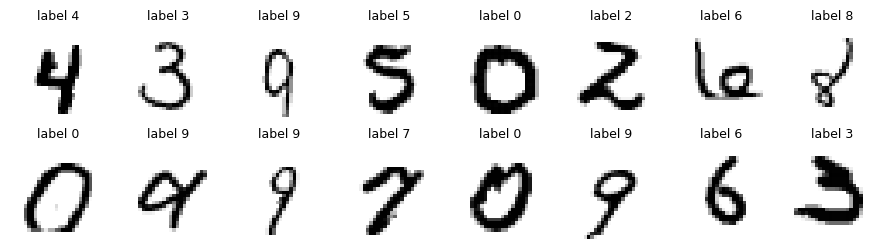

pixels exactly 0: 0.809   exactly 1: 0.007   strictly between: 0.185


In [2]:
fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for ax, i in zip(axes.ravel(), rng.choice(len(X_train), 16, replace=False)):
    ax.imshow(X_train[i].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(f'label {y_train[i]}', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

share_zero = (X_train == 0).mean()
share_one = (X_train == 1).mean()
print(f'pixels exactly 0: {share_zero:.3f}   exactly 1: {share_one:.3f}   '
      f'strictly between: {1 - share_zero - share_one:.3f}')

About 81% of all pixels are exactly 0 (background) and 0.7% are exactly 1;
the remaining 18.5% are grey levels on the edges of strokes. Both parts of the
notebook model these same numbers, with different likelihoods: Part A treats
them as Gaussian, Part B as Bernoulli targets.

# Part A — Probabilistic PCA in closed form

## A1. The model and its maximum-likelihood fit

Probabilistic PCA (deck, *Linear-Gaussian Latent Model*) is
$$z\sim\mathcal N(0,I_r),\qquad x\mid z\sim\mathcal N(Wz+\mu,\;\sigma^2I_d),\qquad d=784,$$
so $x$ is a signal $Wz$ in the $r$-dimensional column space of $W$, plus
isotropic noise. Integrating $z$ out gives $x\sim\mathcal N(\mu,\,WW^\top+\sigma^2I_d)$.
Tipping and Bishop (1999) showed that the likelihood is maximized in closed
form. With $\lambda_1\ge\dots\ge\lambda_d$ and $u_1,\dots,u_d$ the eigenvalues
and eigenvectors of the sample covariance,
$$\widehat\mu=\bar x,\qquad
\widehat\sigma^2=\frac1{d-r}\sum_{j>r}\lambda_j,\qquad
\widehat W=U_r\bigl(\Lambda_r-\widehat\sigma^2I_r\bigr)^{1/2},$$
up to a rotation $\widehat W R$. The noise variance is the average variance
*left over* outside the top $r$ directions, and column $j$ of $\widehat W$ is
$u_j$ stretched to length $a_j=\sqrt{\lambda_j-\widehat\sigma^2}$, so that
$WW^\top+\sigma^2I$ has exactly the eigenvalue $\lambda_j$ along $u_j$
(deck, *Why That Covariance Is PCA*).

The cell computes the $784\times784$ covariance of the 60,000 training images
in double precision, fits $r=2$ and $r=20$, and prints $\widehat\sigma^2$, the
top eigenvalues, and the share of the total variance the $r$ directions hold.
It also checks that the fitted covariance reproduces the top eigenvalues and
that our log-density formula agrees with SciPy's.

In [3]:
from scipy.stats import multivariate_normal
from matplotlib import patheffects
from matplotlib.patches import Ellipse

d = 784
X64, X64_test = X_train.astype(np.float64), X_test.astype(np.float64)
mu_hat = X64.mean(0)
Sigma_hat = (X64 - mu_hat).T @ (X64 - mu_hat) / len(X64)
eigenvalues, eigenvectors = np.linalg.eigh(Sigma_hat)
eigenvalues, eigenvectors = eigenvalues[::-1].clip(0), eigenvectors[:, ::-1]

def closed_form(r):
    """Tipping-Bishop maximum likelihood: W = U_r (Lambda_r - sigma2 I)^(1/2)."""
    sigma2 = eigenvalues[r:].mean()
    return eigenvectors[:, :r] * np.sqrt(eigenvalues[:r] - sigma2), sigma2

def ppca_log_density(X, W, sigma2):
    """log N(x; mu_hat, W W^T + sigma2 I) per row, without forming the 784 x 784 inverse."""
    r = W.shape[1]
    M = W.T @ W + sigma2 * np.eye(r)
    centred = X - mu_hat
    projected = centred @ W
    quadratic = ((centred ** 2).sum(1) - (projected @ np.linalg.inv(M) * projected).sum(1)) / sigma2
    log_det = (d - r) * np.log(sigma2) + np.linalg.slogdet(M)[1]
    return -0.5 * (d * np.log(2 * np.pi) + log_det + quadratic)

fits = {r: closed_form(r) for r in (2, 20)}
total_variance = eigenvalues.sum()
for r, (W, sigma2) in fits.items():
    C = W @ W.T + sigma2 * np.eye(d)
    top = np.sort(np.linalg.eigvalsh(C))[::-1][:r + 1]
    assert np.allclose(top[:r], eigenvalues[:r]) and np.isclose(top[r], sigma2)
    print(f'r={r:2d}: sigma^2 = {sigma2:.4f} (noise sd {np.sqrt(sigma2):.3f})   '
          f'top r directions hold {eigenvalues[:r].sum() / total_variance:.1%} of the variance   '
          f'test log density {ppca_log_density(X64_test, W, sigma2).mean():7.1f} nats per image')
print('top five eigenvalues:', eigenvalues[:5].round(3), '  total variance:', round(total_variance, 2))

W2, sigma2_2 = fits[2]
check = multivariate_normal(mu_hat, W2 @ W2.T + sigma2_2 * np.eye(d), allow_singular=False)
assert np.allclose(ppca_log_density(X64_test[:5], W2, sigma2_2), check.logpdf(X64_test[:5]))

r= 2: sigma^2 = 0.0561 (noise sd 0.237)   top r directions hold 16.8% of the variance   test log density    14.4 nats per image
r=20: sigma^2 = 0.0246 (noise sd 0.157)   top r directions hold 64.4% of the variance   test log density   306.5 nats per image
top five eigenvalues: [5.117 3.741 3.253 2.842 2.567]   total variance: 52.73


With $r=2$ the noise variance is $\widehat\sigma^2=0.0561$, a noise standard
deviation of 0.24 on every pixel, because two directions hold only 16.8% of
the total variance of 52.73; the other 782 eigenvalues average to 0.056. With
$r=20$ the 20 directions hold 64.4% and $\widehat\sigma^2$ drops to 0.0246.
The asserts confirm that $\widehat W\widehat W^\top+\widehat\sigma^2I$ has
exactly the sample eigenvalues $\lambda_1,\dots,\lambda_r$ along the top
directions and $\widehat\sigma^2$ everywhere else, and that our log density
matches SciPy's.

**The unit: nats.** Every log likelihood, ELBO and KL divergence in this
notebook uses the natural logarithm, and a quantity measured that way is in
**nats** (with $\log_2$ it would be in bits; 1 nat $=1/\ln2\approx1.44$
bits). Read differences: a model whose log likelihood is $\Delta$ nats higher
on an image makes that image $e^{\Delta}$ times as probable, so 1 nat is a
factor of $e\approx2.7$ and 10 nats a factor of about 22,000. Numbers are
reported per image, the sum over its 784 pixels; divide by 784 for nats per
pixel. A KL divergence in nats is the expected log ratio of two densities,
so a KL of 2.6 nats means that, on average over $q$, $q$ puts about
$e^{2.6}\approx13$ times as much density on its draws as the prior does.

The test log density, 14.4 nats per image for $r=2$ and 306.5 for $r=20$, is
a log *density* over continuous pixel values. It is positive because each
pixel's Gaussian is narrow, and it rises whenever $\sigma^2$ shrinks. Part B
reports log *probabilities* of a Bernoulli model for the same pixels, on a
different scale, so the two numbers cannot be compared; we use PPCA here for
its posterior, which is where it is exact.

## A2. The posterior is a formula

Because prior and likelihood are Gaussian and the map is linear, the
posterior of the code is Gaussian (Appendix A.1):
$$p(z\mid x)=\mathcal N\bigl(M^{-1}W^\top(x-\mu),\;\sigma^2M^{-1}\bigr),\qquad M=W^\top W+\sigma^2I_r .$$
Its covariance $S=\sigma^2M^{-1}$ does not involve $x$: **every image has the
same posterior spread**. With the orthogonal columns of $\widehat W$, $M$ is
diagonal and the posterior separates by coordinate (Appendix A.3),
$$z_j\mid x\sim\mathcal N\!\Bigl(\frac{a_j}{a_j^2+\sigma^2}\,u_j^\top(x-\mu),\;\frac{\sigma^2}{a_j^2+\sigma^2}\Bigr),$$
the PCA score $u_j^\top(x-\mu)$ shrunk towards zero.

The cell checks the formula two independent ways for $r=2$.

1. **Gaussian conditioning.** $(z,x)$ is jointly Gaussian with
   $\operatorname{Cov}(z)=I$, $\operatorname{Cov}(z,x)=W^\top$ and
   $\operatorname{Cov}(x)=C=WW^\top+\sigma^2I$, so the textbook conditioning
   formulas give mean $W^\top C^{-1}(x-\mu)$ and covariance $I-W^\top C^{-1}W$,
   computed here with the full $784\times784$ matrix $C$.
2. **Bayes' rule on a grid.** Evaluate $\log p(z)+\log p(x\mid z)$ on a fine
   grid of codes, normalize numerically, and compute the mean and covariance
   of the resulting table. This uses no Gaussian algebra at all, and we will
   reuse it for the VAE in B6e, where no formula exists.

In [4]:
def ppca_posterior(X, W, sigma2):
    """Posterior means (one row per image) and the shared covariance S."""
    M = W.T @ W + sigma2 * np.eye(W.shape[1])
    return (X - mu_hat) @ W @ np.linalg.inv(M), sigma2 * np.linalg.inv(M)

first_of_each = [int(np.flatnonzero(y_test == digit)[0]) for digit in range(10)]
x0 = X64_test[first_of_each[0]]
mean_formula, S2 = ppca_posterior(x0[None], W2, sigma2_2)
mean_formula = mean_formula[0]

# 1. Brute-force Gaussian conditioning with the full 784 x 784 covariance.
C2 = W2 @ W2.T + sigma2_2 * np.eye(d)
mean_conditioning = W2.T @ np.linalg.solve(C2, x0 - mu_hat)
cov_conditioning = np.eye(2) - W2.T @ np.linalg.solve(C2, W2)

# 2. Bayes' rule on a 401 x 401 grid of codes, normalized numerically.
def grid_posterior(log_joint, centre, half_width, n=401):
    """Normalize log_joint(Z) over a square grid; return grid axes, density, mean, cov, log evidence."""
    axis_1 = np.linspace(centre[0] - half_width, centre[0] + half_width, n)
    axis_2 = np.linspace(centre[1] - half_width, centre[1] + half_width, n)
    Z = np.stack(np.meshgrid(axis_1, axis_2), -1).reshape(-1, 2)
    values = log_joint(Z)
    cell = (axis_1[1] - axis_1[0]) * (axis_2[1] - axis_2[0])
    log_evidence = np.logaddexp.reduce(values) + np.log(cell)
    weights = np.exp(values - values.max()); weights /= weights.sum()
    mean = weights @ Z
    cov = (weights[:, None] * (Z - mean)).T @ (Z - mean)
    return axis_1, axis_2, weights.reshape(n, n) / cell, mean, cov, log_evidence

def ppca_log_joint(x, W, sigma2):
    def log_joint(Z):
        residual = (x - mu_hat)[None, :] - Z @ W.T
        return (-0.5 * (Z ** 2).sum(1) - np.log(2 * np.pi)
                - 0.5 * (residual ** 2).sum(1) / sigma2 - 0.5 * d * np.log(2 * np.pi * sigma2))
    return log_joint

_, _, _, mean_grid, cov_grid, log_evidence_grid = grid_posterior(
    ppca_log_joint(x0, W2, sigma2_2), mean_formula, 6 * np.sqrt(S2.diagonal().max()))

print('posterior mean   formula', mean_formula.round(5), '  conditioning', mean_conditioning.round(5),
      '  grid', mean_grid.round(5))
print('posterior cov    formula', S2.round(6).tolist())
print('                 conditioning', cov_conditioning.round(6).tolist())
print('                 grid', cov_grid.round(6).tolist())
print(f'log p(x): grid {log_evidence_grid:.3f}   closed form {ppca_log_density(x0[None], W2, sigma2_2)[0]:.3f}')
assert np.allclose(mean_formula, mean_conditioning) and np.allclose(S2, cov_conditioning)
assert np.allclose(mean_grid, mean_formula, atol=1e-3) and np.allclose(cov_grid, S2, atol=1e-4)
assert abs(log_evidence_grid - ppca_log_density(x0[None], W2, sigma2_2)[0]) < 1e-3

# Appendix A.3: the posterior mean is the shrunk PCA score.
a = np.sqrt(eigenvalues[:2] - sigma2_2)
shrunk_scores = (a / (a ** 2 + sigma2_2)) * ((x0 - mu_hat) @ eigenvectors[:, :2])
print('shrink factor a_j^2 / (a_j^2 + sigma^2):', (a ** 2 / (a ** 2 + sigma2_2)).round(4),
      '   posterior sd per coordinate:', np.sqrt(S2.diagonal()).round(4))
assert np.allclose(shrunk_scores, mean_formula)

posterior mean   formula [-2.1274   0.22726]   conditioning [-2.1274   0.22726]   grid [-2.1274   0.22726]
posterior cov    formula [[0.010963, 0.0], [0.0, 0.014994]]
                 conditioning [[0.010963, -0.0], [-0.0, 0.014994]]
                 grid [[0.010963, -0.0], [-0.0, 0.014994]]
log p(x): grid 56.662   closed form 56.662
shrink factor a_j^2 / (a_j^2 + sigma^2): [0.989 0.985]    posterior sd per coordinate: [0.1047 0.1224]


All three methods agree to every printed digit. The posterior mean of the
first test image (a 0) is $(-2.1274,\,0.2273)$, and its covariance is
$\operatorname{diag}(0.010963,\,0.014994)$, by the formula, by Gaussian
conditioning in 784 dimensions, and by brute-force normalization of
$p(z)\,p(x\mid z)$ on a grid. The grid's normalizing constant reproduces
$\log p(x)=56.662$ from A1. The covariance is diagonal, with entries
$\sigma^2/\lambda_j$, and the shrinkage factors are 0.989 and 0.985: the
posterior mean is the PCA score $u_j^\top(x-\mu)$ divided by $a_j$ and shrunk
by about 1%. The posterior standard deviations, 0.105 and 0.122, say how
precisely the image pins down its two-number code.

## A3. Seeing the posterior

With $r=2$ the code is a point in the plane, so the two objects the E-step
produces can both be drawn. They answer two different questions, and the
next two cells take them one at a time.

* **Where does each image land?** The posterior mean $m_i=\mathbb E[z\mid x_i]$ is a
  single point per image. Plotting it for all 10,000 test images, coloured by
  the digit label the model never saw, shows how PPCA lays out the ten
  classes in its two-dimensional code space.
* **How sure is the model about one image's code?** The posterior
  $\mathcal N(m_i,S)$ is a whole distribution per image. For three individual
  images we draw it next to the prior $\mathcal N(0,I)$, to see how much
  observing the image narrows down its code.

The first cell draws the code space: one dot per test image at its posterior
mean, a colour and a label per digit, and the dashed circle of radius 2
inside which the prior puts $1-e^{-2}\approx86\%$ of its mass. Look at which digits get their
own region and which share one.

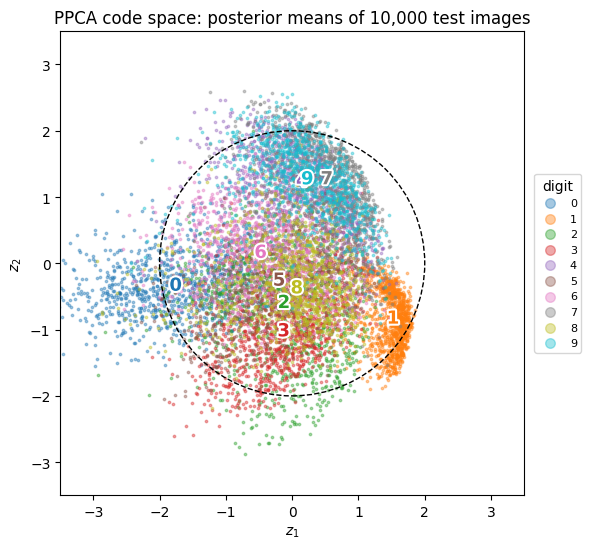

digit,0,1,2,3,4,5,6,7,8,9
median z_1,-1.76,1.52,-0.12,-0.13,0.15,-0.20,-0.48,0.52,0.07,0.23
median z_2,-0.34,-0.83,-0.60,-1.03,1.24,-0.26,0.16,1.27,-0.38,1.27


spread of the posterior means across images (sd): [1.01  1.022]    A.3 prediction sqrt(a_j^2 / lambda_j): [0.995 0.992]
share of test images inside the prior circle of radius 2: 0.880


In [5]:
ppca_means, _ = ppca_posterior(X64_test, W2, sigma2_2)
digit_colours = plt.cm.tab10(np.arange(10))

fig, ax = plt.subplots(figsize=(6.6, 5.6))
for digit in range(10):
    mask = y_test == digit
    ax.scatter(ppca_means[mask, 0], ppca_means[mask, 1], s=3, alpha=0.4, color=digit_colours[digit],
               label=str(digit), rasterized=True)
for digit in range(10):
    centre = np.median(ppca_means[y_test == digit], axis=0)
    ax.annotate(str(digit), centre, ha='center', va='center', fontsize=13, fontweight='bold',
                color=digit_colours[digit], path_effects=[patheffects.withStroke(linewidth=3, foreground='white')])
ax.add_patch(plt.Circle((0, 0), 2, fill=False, color='k', ls='--', lw=1))
ax.set(xlabel='$z_1$', ylabel='$z_2$', aspect='equal', xlim=(-3.5, 3.5), ylim=(-3.5, 3.5),
       title='PPCA code space: posterior means of 10,000 test images')
ax.legend(title='digit', markerscale=4, fontsize=8, loc='center left', bbox_to_anchor=(1.01, .5))
plt.tight_layout(); plt.show()

centres = pd.DataFrame([np.median(ppca_means[y_test == digit], axis=0) for digit in range(10)],
                       columns=['median z_1', 'median z_2']).round(2)
centres.index.name = 'digit'
display(centres.T)
print('spread of the posterior means across images (sd):', ppca_means.std(0).round(3),
      '   A.3 prediction sqrt(a_j^2 / lambda_j):', np.sqrt(a ** 2 / eigenvalues[:2]).round(3))
print(f'share of test images inside the prior circle of radius 2: {(np.linalg.norm(ppca_means, axis=1) < 2).mean():.3f}')
assert np.allclose(ppca_means.std(0), np.sqrt(a ** 2 / eigenvalues[:2]), atol=0.06)

Each digit's median position is marked with its label. The 1s form a
tight band on the right (median $(1.52,-0.83)$) and the 0s spread out to the
left (median $(-1.76,-0.34)$); 4, 7 and 9 share the top of the plane (all
three medians at $z_2\approx1.25$), and 2, 3, 5, 6 and 8 pile up in the
middle and lower half. Two linear directions cannot give ten shapes ten
separate regions, so only the digits that differ most in their pixels, 0
and 1, are pulled apart.

The cloud also has the shape the model assumes for codes. The posterior
means spread with standard deviations 1.01 and 1.02 (Appendix A.3 predicts
0.995 and 0.992 from the training data), and 88.0% of the test images land
inside the radius-2 circle where the prior $\mathcal N(0,I)$ puts 86% of its
mass: the encoded data look like prior draws, which is what makes decoding
prior draws produce digit-like images in A4.

**The posterior of one image.** The second cell picks three test images, the
first 0, the first 1 and the first 7, and draws, for each of them:

* left, the image itself;
* middle, the code plane with the prior $\mathcal N(0,I)$ as grey contours
  (1 and 2 standard deviations) and the image's posterior
  $\mathcal N(m_i,S)$ as a filled density in the digit's colour, on top of the
  faint cloud of all posterior means from the previous cell;
* right, a zoom into a $0.9\times0.9$ window around $m_i$, the same size for
  all three images, with the 1- and 2-standard-deviation contours of the
  posterior and the posterior means of the other test images that fall in the
  window.

Look at how small the posterior is compared with the prior, and compare the
three zoomed panels with each other.

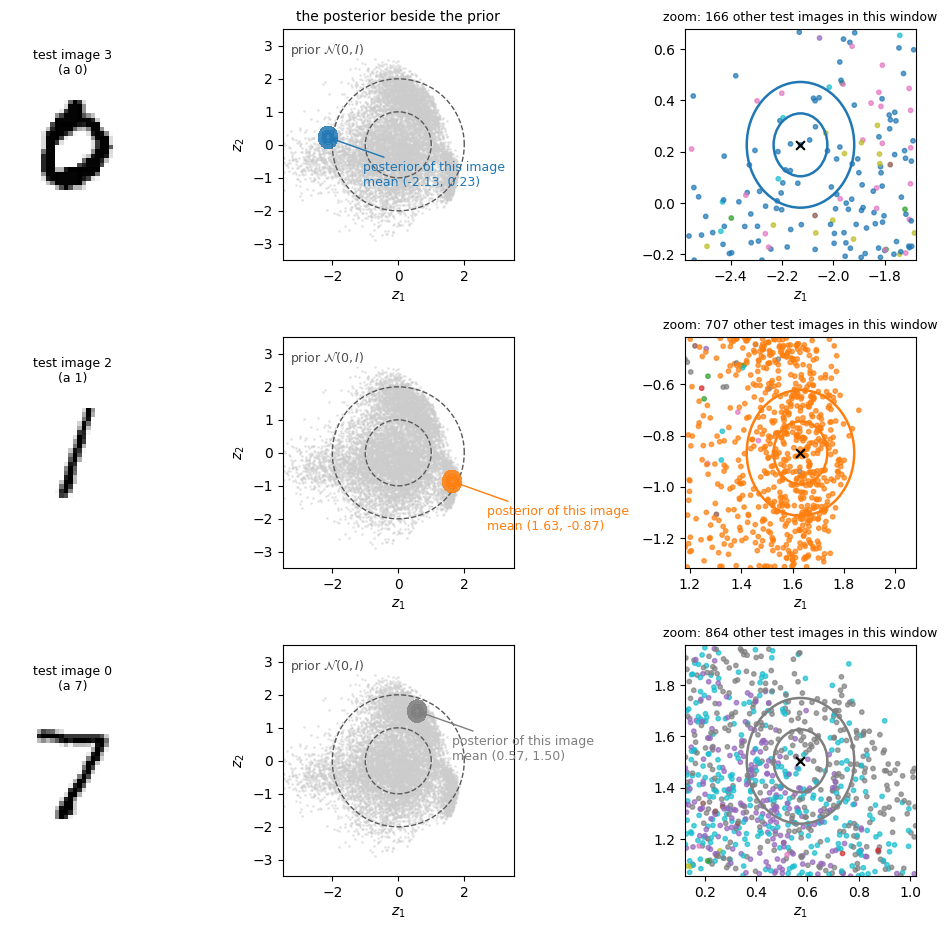

,digit,posterior mean,posterior sd,other images inside its 2-sd ellipse,share of those with the same digit
test image,,,,,
3,0,"[-2.127, 0.227]","[0.105, 0.122]",24,0.79
2,1,"[1.631, -0.867]","[0.105, 0.122]",307,0.99
0,7,"[0.573, 1.505]","[0.105, 0.122]",224,0.44


posterior area / prior area (ratio of 2-sd ellipses) = sqrt(det S) = 0.0128


In [6]:
def gaussian_density(points, mean, cov):
    """Density of N(mean, cov) at the rows of points (2-D)."""
    diff = points - mean
    inverse = np.linalg.inv(cov)
    return np.exp(-0.5 * np.einsum('...i,ij,...j->...', diff, inverse, diff)) / (2 * np.pi * np.sqrt(np.linalg.det(cov)))

def add_ellipse(ax, centre, cov, scale, **style):
    """The scale-standard-deviation contour of N(centre, cov)."""
    values, vectors = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vectors[1, -1], vectors[0, -1]))
    ax.add_patch(Ellipse(centre, 2 * scale * np.sqrt(values[-1]), 2 * scale * np.sqrt(values[0]),
                         angle=angle, fill=False, **style))

chosen = [first_of_each[d] for d in (0, 1, 7)]
grid_wide = np.linspace(-3.5, 3.5, 351)
G1, G2 = np.meshgrid(grid_wide, grid_wide)
plane = np.stack([G1, G2], axis=-1)
half = 0.45

fig, axes = plt.subplots(3, 3, figsize=(9.6, 9.4), gridspec_kw={'width_ratios': [0.45, 1, 1]})
for row, index in enumerate(chosen):
    digit, m_i = y_test[index], ppca_means[index]
    colour = digit_colours[digit]
    axes[row, 0].imshow(X_test[index].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    axes[row, 0].set_title(f'test image {index}\n(a {digit})', fontsize=9); axes[row, 0].axis('off')

    ax = axes[row, 1]
    ax.scatter(ppca_means[:, 0], ppca_means[:, 1], s=1, color='0.8', alpha=0.4, rasterized=True)
    for scale in (1, 2):
        add_ellipse(ax, np.zeros(2), np.eye(2), scale, color='0.35', lw=1, ls='--')
    posterior = gaussian_density(plane, m_i, S2)
    ax.contourf(G1, G2, posterior, levels=np.linspace(posterior.max() * 0.02, posterior.max(), 6),
                colors=[colour], alpha=0.85)
    ax.annotate('prior $\\mathcal{N}(0,I)$', (0.03, 0.95), xycoords='axes fraction', color='0.3', fontsize=9, va='top')
    ax.annotate(f'posterior of this image\nmean ({m_i[0]:.2f}, {m_i[1]:.2f})', m_i, xytext=(25, -35),
                textcoords='offset points', fontsize=9, color=colour,
                arrowprops=dict(arrowstyle='->', color=colour))
    ax.set(aspect='equal', xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), xlabel='$z_1$', ylabel='$z_2$')

    ax = axes[row, 2]
    near = np.all(np.abs(ppca_means - m_i) < half, axis=1)
    ax.scatter(ppca_means[near, 0], ppca_means[near, 1], s=10, color=digit_colours[y_test[near]], alpha=0.7)
    for scale in (1, 2):
        add_ellipse(ax, m_i, S2, scale, color=colour, lw=1.8)
    ax.scatter(*m_i, marker='x', color='k', s=40, zorder=4)
    ax.set(aspect='equal', xlim=(m_i[0] - half, m_i[0] + half), ylim=(m_i[1] - half, m_i[1] + half), xlabel='$z_1$')
    ax.set_title(f'zoom: {near.sum() - 1} other test images in this window', fontsize=9)
axes[0, 1].set_title('the posterior beside the prior', fontsize=10)
plt.tight_layout(); plt.show()

rows = []
for index in chosen:
    near2 = np.einsum('ij,jk,ik->i', ppca_means - ppca_means[index], np.linalg.inv(S2), ppca_means - ppca_means[index]) < 4
    rows.append({'test image': index, 'digit': y_test[index], 'posterior mean': ppca_means[index].round(3).tolist(),
                 'posterior sd': np.sqrt(S2.diagonal()).round(3).tolist(),
                 'other images inside its 2-sd ellipse': int(near2.sum() - 1),
                 'share of those with the same digit': round(float((y_test[near2] == y_test[index]).sum() - 1) / max(1, near2.sum() - 1), 2)})
display(pd.DataFrame(rows).set_index('test image'))
print(f'posterior area / prior area (ratio of 2-sd ellipses) = sqrt(det S) = {np.sqrt(np.linalg.det(S2)):.4f}')

**How sure the model is.** Each posterior is a small blob in the middle
panels: its standard deviations are 0.105 and 0.122, so its 2-sd ellipse
covers 0.0128 of the area of the prior's. Observing 784 pixels pins the two
code numbers down to about $\pm0.2$, out of a prior range of about $\pm2$.

**The same certainty for every image.** The three zoomed panels show one
ellipse, translated to three places. $S=\sigma^2M^{-1}$ does not involve $x$
(Appendix A.1), so PPCA is exactly as sure about the code of a clean 1 as
about the code of an ambiguous 7. This is special to the linear Gaussian
model; in Part B the encoder outputs a different $\sigma_\phi(x)$ for every
image.

**What the certainty does not give.** The table counts the test images whose
posterior means fall inside each 2-sd ellipse. The 1's ellipse holds 307
other images, 99% of them 1s; the 0's holds 24, 79% of them 0s; the 7's holds
224, and only 44% of them are 7s, the rest mostly 9s and 4s (the cyan and
purple points in its zoom). The model knows precisely where the 7 lands, and
that place is shared with other digits. The limitation is the linear map from
code to image, which the VAE in Part B replaces by a network.

## A4. What the linear decoder can generate

Generation is the same two draws as for a VAE: $z\sim\mathcal N(0,I)$, then
$x\mid z\sim\mathcal N(Wz+\mu,\sigma^2I)$. The cell shows three things for the
fitted PPCA models:

1. the decoder mean $\widehat\mu+\widehat Wz$ over a $10\times10$ grid of codes
   with $r=2$, spaced by prior quantiles as in B6b below;
2. the decoder means of ten prior draws with $r=20$; and
3. full samples $x=\widehat\mu+\widehat Wz+\epsilon$ for the same ten codes.

Pixels are clipped to $[0,1]$ for display only.

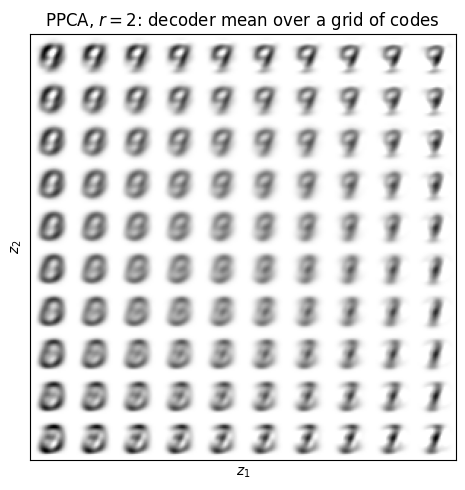

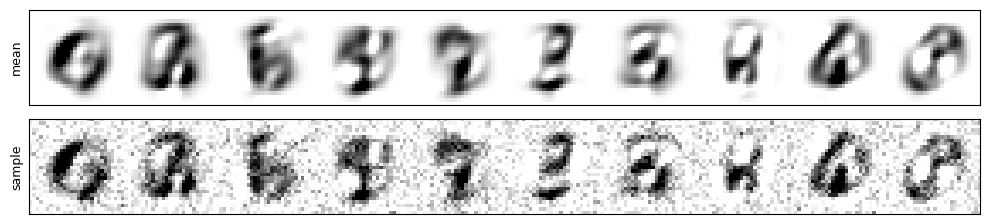

share of sampled pixels outside [0, 1]: 0.382


In [7]:
def show_grid(ax, images, columns):
    tiles = [np.asarray(image).reshape(28, 28) for image in images]
    rows = [np.hstack(tiles[k:k + columns]) for k in range(0, len(tiles), columns)]
    ax.imshow(np.vstack(rows).clip(0, 1), cmap='gray_r', vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])

quantiles = norm.ppf(np.linspace(0.05, 0.95, 10))
grid_codes = np.array([[z1, z2] for z2 in quantiles[::-1] for z1 in quantiles])
fig, ax = plt.subplots(figsize=(5, 5))
show_grid(ax, mu_hat + grid_codes @ W2.T, 10)
ax.set(xlabel='$z_1$', ylabel='$z_2$', title='PPCA, $r=2$: decoder mean over a grid of codes')
plt.tight_layout(); plt.show()

W20, sigma2_20 = fits[20]
prior_rng = np.random.default_rng(SEED + 4)
z20 = prior_rng.standard_normal((10, 20))
means_20 = mu_hat + z20 @ W20.T
samples_20 = means_20 + np.sqrt(sigma2_20) * prior_rng.standard_normal((10, d))
fig, axes = plt.subplots(2, 1, figsize=(10, 2.4))
show_grid(axes[0], means_20, 10); axes[0].set_ylabel('mean', fontsize=9)
show_grid(axes[1], samples_20, 10); axes[1].set_ylabel('sample', fontsize=9)
plt.tight_layout(); plt.show()
print('share of sampled pixels outside [0, 1]:', round(float(((samples_20 < 0) | (samples_20 > 1)).mean()), 3))

Every decoded tile is the mean image plus a weighted sum of two
eigen-images, so the grid shows superpositions: a 0 with a 9 inside it on
the left, 1-like strokes on the right, a 3-like ghost at the bottom. Nothing
in a linear decoder can draw a stroke in one place *or* another; it can only
add and subtract fixed images. With $r=20$ the decoder means are blotchy
shapes, a few recognizable (a 0, a 2, a 6, a 7), with ink that spills outside
$[0,1]$, and the full samples add independent noise of standard deviation
0.16 to every pixel, background included: 38.2% of the sampled pixels fall
outside $[0,1]$. A Gaussian with one variance for every pixel describes
neither the clean background nor the sharp strokes. Part B changes both
pieces: a network replaces $Wz+\mu$, and a Bernoulli likelihood replaces the
isotropic Gaussian. The price is the posterior formula of A2.

# Part B — The variational autoencoder

## B1. A likelihood for pixels

A VAE keeps the structure $p(z)\,p_\theta(x\mid z)$ and lets a network
$f_\theta$ produce the parameters of $p_\theta(x\mid z)$. Like the PyTorch
example, we use a product of Bernoullis: the decoder returns one logit $s_j$
per pixel, $p_j=\mathrm{sigmoid}(s_j)$, and
$$-\log p_\theta(x\mid z)=-\sum_{j=1}^{784}\bigl[x_j\log p_j+(1-x_j)\log(1-p_j)\bigr],$$
the binary cross-entropy summed over pixels. A Bernoulli likelihood describes
pixels that are exactly 0 or 1; for the 18.5% of grey pixels counted above,
the common practice we follow is to use the intensity itself as a soft
target. Its minimum over $p_j$ is then above zero, so the reconstruction
numbers below are best read as a training loss in nats per image. The
comparisons inside Part B all use the same loss.

## B2. The encoder, the decoder, and their sizes

The encoder outputs the parameters of a diagonal Gaussian,
$$q_\phi(z\mid x)=\mathcal N\bigl(\mu_\phi(x),\operatorname{diag}(\sigma^2_\phi(x))\bigr),$$
as $2r$ numbers: $r$ means and $r$ log variances. Predicting
$\log\sigma^2_\phi$ lets the network output any real number while
$\sigma_\phi=\exp(\tfrac12\log\sigma^2_\phi)$ stays positive. The decoder maps
a code $z\in\mathbb R^r$ to 784 logits, one Bernoulli parameter per pixel.

The class below follows the PyTorch example layer for layer, with one change
for numerical stability: the decoder returns logits, and the loss uses
`binary_cross_entropy_with_logits`, which computes the same quantity as
`sigmoid` followed by `binary_cross_entropy` without forming $\log p_j$ for
$p_j$ near 0 or 1.

The cell lists every parameter tensor and pushes a batch of 64 images through
the model. Check that the encoder produces $2r=40$ numbers per image and that
the decoder returns 784.

In [8]:
class VAE(nn.Module):
    """Gaussian encoder q_phi(z|x) and Bernoulli decoder p_theta(x|z)."""
    def __init__(self, latent=20, hidden=400):
        super().__init__()
        self.latent = latent
        self.body = nn.Sequential(nn.Linear(784, hidden), nn.ReLU())   # phi
        self.mean = nn.Linear(hidden, latent)                          # phi
        self.log_variance = nn.Linear(hidden, latent)                  # phi
        self.decoder = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(),
                                     nn.Linear(hidden, 784))           # theta

    def encode(self, x):
        h = self.body(x)
        return self.mean(h), self.log_variance(h)

    def reparameterize(self, mean, log_variance):
        epsilon = torch.randn_like(mean)                 # the randomness, outside phi
        return mean + torch.exp(0.5 * log_variance) * epsilon

    def forward(self, x):
        mean, log_variance = self.encode(x)
        z = self.reparameterize(mean, log_variance)
        return self.decoder(z), mean, log_variance       # logits, then q's parameters

model = VAE()
rows = [{'parameter': name, 'shape': tuple(p.shape), 'count': p.numel(),
         'network': 'decoder (theta)' if name.startswith('decoder') else 'encoder (phi)'}
        for name, p in model.named_parameters()]
table = pd.DataFrame(rows)
display(table)
print(table.groupby('network')['count'].sum())
total = table['count'].sum()
print(f'total parameters: {total:,}')
assert total == (784 * 400 + 400) + 2 * (400 * 20 + 20) + (20 * 400 + 400) + (400 * 784 + 784)

x = torch.tensor(X_train[:64])
mean, log_variance = model.encode(x)
z = model.reparameterize(mean, log_variance)
logits = model.decoder(z)
print('image   ', tuple(x.shape))
print('mean    ', tuple(mean.shape), '  log variance', tuple(log_variance.shape))
print('code z  ', tuple(z.shape))
print('logits  ', tuple(logits.shape))
assert logits.shape == (64, 784) and z.shape == (64, 20)

,parameter,shape,count,network
0,body.0.weight,"(400, 784)",313600,encoder (phi)
1,body.0.bias,"(400,)",400,encoder (phi)
2,mean.weight,"(20, 400)",8000,encoder (phi)
3,mean.bias,"(20,)",20,encoder (phi)
4,log_variance.weight,"(20, 400)",8000,encoder (phi)
5,log_variance.bias,"(20,)",20,encoder (phi)
6,decoder.0.weight,"(400, 20)",8000,decoder (theta)
7,decoder.0.bias,"(400,)",400,decoder (theta)
8,decoder.2.weight,"(784, 400)",313600,decoder (theta)
9,decoder.2.bias,"(784,)",784,decoder (theta)


network
decoder (theta)    322784
encoder (phi)      330040
Name: count, dtype: int64
total parameters: 652,824
image    (64, 784)
mean     (64, 20)   log variance (64, 20)
code z   (64, 20)
logits   (64, 784)


The model has 652,824 parameters, split almost evenly: 330,040 in the
encoder and 322,784 in the decoder. Each side is dominated by one
$784\times400$ matrix of 313,600 weights, the layer that touches every pixel.
For one image the encoder hands over $2r=40$ numbers, the 20 means and 20
log variances of $q_\phi(z\mid x)$; the code $z$ has 20 entries, and the
decoder returns 784 logits. This is the slide *Size of the Two Networks*,
with $d=784$ and $r=20$.

## B3. The three formulas under the loss

For one image the training loss is the negative ELBO,
$$\mathcal J(x)=\underbrace{-\mathbb E_{q_\phi(z\mid x)}\bigl[\log p_\theta(x\mid z)\bigr]}_{\text{reconstruction}}
+\underbrace{D_{\rm KL}\bigl(q_\phi(z\mid x)\,\|\,p(z)\bigr)}_{\text{KL}},\qquad p(z)=\mathcal N(0,I_r).$$
Three facts make it computable and differentiable. We check each one
numerically before trusting it inside a training loop.

### B3a. The KL term has a closed form (Appendix A.8)

For $q=\mathcal N(\mu,\operatorname{diag}(\sigma^2))$ and $p=\mathcal N(0,I)$,
$$D_{\rm KL}(q\,\|\,p)=\frac12\sum_{j=1}^r\bigl(\mu_j^2+\sigma_j^2-1-\log\sigma_j^2\bigr).$$
The definition is $D_{\rm KL}(q\|p)=\mathbb E_q[\log q(z)-\log p(z)]$, which we
can also estimate by averaging $\log q(z)-\log p(z)$ over many draws
$z\sim q$. The cell compares the formula, the Monte Carlo average over
200,000 draws, and PyTorch's own `kl_divergence`, for a three-dimensional $q$.
Look at whether the Monte Carlo value lands within a few standard errors of
the formula.

In [9]:
from torch.distributions import Normal, kl_divergence

mu = torch.tensor([0.8, -1.5, 0.0])
sigma = torch.tensor([0.5, 1.0, 2.0])

closed_form = 0.5 * (mu**2 + sigma**2 - 1 - torch.log(sigma**2))
q, p = Normal(mu, sigma), Normal(torch.zeros(3), torch.ones(3))
draws = q.sample((200_000,))
log_ratio = (q.log_prob(draws) - p.log_prob(draws)).sum(1)
monte_carlo, standard_error = log_ratio.mean(), log_ratio.std() / np.sqrt(len(draws))

print('closed form, per coordinate:', closed_form.numpy().round(4),
      ' total', round(closed_form.sum().item(), 4))
print(f'Monte Carlo total: {monte_carlo:.4f}  (standard error {standard_error:.4f})')
print('torch kl_divergence total:  ', round(kl_divergence(q, p).sum().item(), 4))
assert abs(monte_carlo - closed_form.sum()) < 4 * standard_error
assert torch.allclose(kl_divergence(q, p), closed_form)

closed form, per coordinate: [0.6381 1.125  0.8069]  total 2.57
Monte Carlo total: 2.5738  (standard error 0.0060)
torch kl_divergence total:   2.57


The closed form gives $0.638+1.125+0.807=2.570$ nats, and PyTorch's
`kl_divergence` returns the same numbers. The Monte Carlo average is 2.574
with a standard error of 0.006, so it lies within one standard error of the
formula. Every coordinate contributes a positive amount: the first because
its mean is off zero and its spread is too small, the second because of the
mean alone, the third because its spread is twice the prior's. The KL term
in the loss therefore needs no sampling at all.

### B3b. Reparameterization draws from the same distribution

Drawing $\epsilon\sim\mathcal N(0,I)$ and setting $z=\mu+\sigma\odot\epsilon$
gives $\mathbb E[z]=\mu$ and $\operatorname{Var}(z_j)=\sigma_j^2$, so $z$ has
exactly the distribution $q$. The cell draws 200,000 codes this way and
prints their sample means and standard deviations next to $\mu$ and
$\sigma$.

In [10]:
epsilon = torch.randn(200_000, 3)
z = mu + sigma * epsilon
print('target mean ', mu.numpy(), '   sample mean', z.mean(0).numpy().round(3))
print('target sd   ', sigma.numpy(), '   sample sd  ', z.std(0).numpy().round(3))
assert torch.allclose(z.mean(0), mu, atol=0.02) and torch.allclose(z.std(0), sigma, atol=0.02)

target mean  [ 0.8 -1.5  0. ]    sample mean [ 0.801 -1.5    0.003]
target sd    [0.5 1.  2. ]    sample sd   [0.5   1.    1.996]


The sample means and standard deviations agree with $\mu$ and $\sigma$ to
about two decimals, the accuracy expected from 200,000 draws. Shifting and
scaling standard normal noise is simply another way of sampling $q$.

### B3c. The pathwise gradient (Appendix A.6)

The point of the rewrite is the gradient. For one coordinate,
$z=\mu+\sigma\epsilon$ gives $\partial z/\partial\mu=1$ and
$\partial z/\partial\sigma=\epsilon$, so for any downstream loss $L(z)$
$$\frac{\partial L}{\partial\mu}=\frac{\partial L}{\partial z},\qquad
\frac{\partial L}{\partial\sigma}=\frac{\partial L}{\partial z}\,\epsilon.$$
Take $L(z)=(z-2)^2$, $\mu=0.5$, $\sigma=0.8$. The cell first fixes one draw
$\epsilon$ and compares autograd with the two hand formulas. It then averages
the per-draw gradients over 100,000 draws. Because
$\mathbb E[(z-2)^2]=(\mu-2)^2+\sigma^2$, the exact gradients of the
expectation are $2(\mu-2)=-3$ and $2\sigma=1.6$; the averages should land
there.

In [11]:
mu_1 = torch.tensor(0.5, requires_grad=True)
sigma_1 = torch.tensor(0.8, requires_grad=True)
eps_1 = torch.tensor(0.37)                     # one fixed draw
z_1 = mu_1 + sigma_1 * eps_1
loss = (z_1 - 2) ** 2
loss.backward()
dL_dz = 2 * (z_1.item() - 2)
print(f'one draw eps = {eps_1.item()}:  z = {z_1.item():.3f}')
print(f'  autograd  dL/dmu = {mu_1.grad.item():.4f}   dL/dsigma = {sigma_1.grad.item():.4f}')
print(f'  by hand   dL/dz  = {dL_dz:.4f}   dL/dz * eps = {dL_dz * eps_1.item():.4f}')
assert abs(mu_1.grad.item() - dL_dz) < 1e-6
assert abs(sigma_1.grad.item() - dL_dz * eps_1.item()) < 1e-6

# Average the per-draw gradient over many draws: an unbiased estimate of the
# gradient of the expectation.
mu_1.grad = None; sigma_1.grad = None
eps_many = torch.randn(100_000)
((mu_1 + sigma_1 * eps_many - 2) ** 2).mean().backward()
print(f'average over 100,000 draws:  d/dmu = {mu_1.grad.item():.3f} (exact -3)   '
      f'd/dsigma = {sigma_1.grad.item():.3f} (exact 1.6)')
assert abs(mu_1.grad.item() + 3) < 0.03 and abs(sigma_1.grad.item() - 1.6) < 0.03

one draw eps = 0.3700000047683716:  z = 0.796
  autograd  dL/dmu = -2.4080   dL/dsigma = -0.8910
  by hand   dL/dz  = -2.4080   dL/dz * eps = -0.8910
average over 100,000 draws:  d/dmu = -2.998 (exact -3)   d/dsigma = 1.599 (exact 1.6)


For the single draw $\epsilon=0.37$ the code is $z=0.796$, so
$\partial L/\partial z=2(z-2)=-2.408$. Autograd returns exactly that for
$\mu$ and $-2.408\times0.37=-0.891$ for $\sigma$: the chain rule of
Appendix A.6 is what autograd executes. Notice that this one-draw gradient
for $\sigma$ is *negative*, while the true gradient of the expectation is
$+1.6$. A single draw is unbiased and noisy, as the slide *Two Networks, One
Bound* warns. Averaged over 100,000 draws the estimates are $-2.998$ and
$1.599$, matching the exact $-3$ and $1.6$.

### B3d. Why the rewrite is needed: `sample()` against `rsample()`

PyTorch distributions offer two ways to draw. `sample()` returns a number
with no record of how it depended on the parameters. `rsample()` (the *r* is
for reparameterized) computes $\mu+\sigma\epsilon$ inside the autograd graph.
The cell draws from $\mathcal N(\mu,\sigma^2)$ both ways and asks whether a
gradient can flow back to $\mu$.

In [12]:
mu_2 = torch.tensor(0.5, requires_grad=True)
plain = Normal(mu_2, 0.8).sample()
reparameterized = Normal(mu_2, 0.8).rsample()
print('sample():  requires_grad =', plain.requires_grad)
print('rsample(): requires_grad =', reparameterized.requires_grad)
((reparameterized - 2) ** 2).backward()
print(f'gradient reaching mu through rsample(): {mu_2.grad.item():.4f}')
assert not plain.requires_grad and reparameterized.requires_grad

sample():  requires_grad = False
rsample(): requires_grad = True
gradient reaching mu through rsample(): -4.9482


A draw made with `sample()` is a constant as far as autograd is concerned:
calling `backward()` through it would leave $\mu$ without a gradient, which
is the problem stated on the slide *Reparameterization Trick*. `rsample()`
keeps the path from $\mu$ to the draw, and the gradient arrives. Our
`VAE.reparameterize` method writes the same computation out by hand.

## B4. Train the VAE

The loss function returns the two terms separately, each averaged over the
images in the batch, so that we can watch them move independently:

* **reconstruction** $-\log p_\theta(x\mid z)$, estimated with **one**
  reparameterized draw $z\sim q_\phi(\cdot\mid x)$ per image;
* **KL** $D_{\rm KL}(q_\phi(z\mid x)\,\|\,p(z))$ from the closed form of 3a.

Their sum is $-\mathcal L$, the negative ELBO, in nats per image. The
argument `beta` multiplies the KL; it stays at 1 until Section B7.

The training loop is the Lecture 11 loop with this loss: shuffle, slice a
minibatch, forward, `backward()`, `step()`. After every epoch we evaluate both
terms on the 10,000 test images, which the model never trains on. The cell
trains for 10 epochs and prints one line per epoch. Look at which of the two
terms moves, and in which direction.

epoch  1  train rec 148.88 KL 15.63  |  test rec 106.34 KL 21.02  -ELBO 127.36  elapsed   1.7s


epoch  2  train rec  99.36 KL 22.40  |  test rec  92.48 KL 23.54  -ELBO 116.02  elapsed   3.6s


epoch  3  train rec  90.71 KL 24.02  |  test rec  87.75 KL 24.11  -ELBO 111.86  elapsed   5.4s


epoch  4  train rec  87.14 KL 24.62  |  test rec  84.45 KL 25.37  -ELBO 109.82  elapsed   7.1s


epoch  5  train rec  85.09 KL 24.90  |  test rec  83.83 KL 24.60  -ELBO 108.43  elapsed   8.8s


epoch  6  train rec  83.73 KL 25.06  |  test rec  82.38 KL 25.55  -ELBO 107.93  elapsed  10.5s


epoch  7  train rec  82.74 KL 25.25  |  test rec  82.03 KL 24.98  -ELBO 107.01  elapsed  12.3s


epoch  8  train rec  81.99 KL 25.30  |  test rec  81.11 KL 25.30  -ELBO 106.41  elapsed  14.0s


epoch  9  train rec  81.41 KL 25.35  |  test rec  80.68 KL 25.26  -ELBO 105.95  elapsed  15.8s


epoch 10  train rec  80.92 KL 25.43  |  test rec  80.34 KL 25.37  -ELBO 105.72  elapsed  17.5s


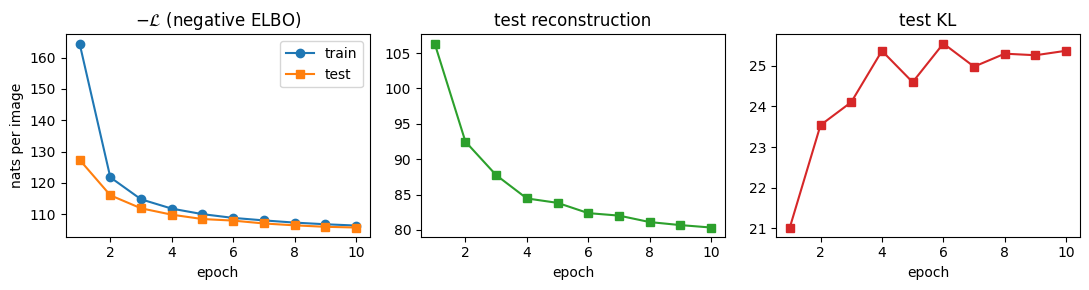

In [13]:
def loss_terms(model, x):
    """Reconstruction and KL, in nats per image, with one draw of z per image."""
    logits, mean, log_variance = model(x)
    reconstruction = F.binary_cross_entropy_with_logits(logits, x, reduction='sum') / len(x)
    kl = 0.5 * torch.sum(mean**2 + log_variance.exp() - 1 - log_variance) / len(x)
    return reconstruction, kl

def evaluate(model, X, batch=2000):
    model.eval()
    totals = np.zeros(2)
    with torch.no_grad():
        for first in range(0, len(X), batch):
            x = X[first:first + batch]
            totals += np.array([t.item() for t in loss_terms(model, x)]) * len(x)
    model.train()
    return totals / len(X)

def train_vae(latent=20, hidden=400, epochs=10, beta=1.0, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    model = VAE(latent, hidden).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    generator = torch.Generator().manual_seed(seed)
    history = []
    start = time.time()
    for epoch in range(epochs):
        order = torch.randperm(len(X_tr), generator=generator).to(device)
        running = np.zeros(2)
        for first in range(0, len(X_tr), 128):
            x = X_tr[order[first:first + 128]]
            reconstruction, kl = loss_terms(model, x)
            optimizer.zero_grad()
            (reconstruction + beta * kl).backward()
            optimizer.step()
            running += np.array([reconstruction.item(), kl.item()]) * len(x)
        train_rec, train_kl = running / len(X_tr)
        test_rec, test_kl = evaluate(model, X_te)
        history.append(dict(epoch=epoch + 1, train_rec=train_rec, train_kl=train_kl,
                            test_rec=test_rec, test_kl=test_kl))
        if verbose:
            print(f'epoch {epoch + 1:2d}  train rec {train_rec:6.2f} KL {train_kl:5.2f}  |  '
                  f'test rec {test_rec:6.2f} KL {test_kl:5.2f}  -ELBO {test_rec + test_kl:6.2f}  '
                  f'elapsed {time.time() - start:5.1f}s')
    model.eval()
    return model, pd.DataFrame(history)

vae, history = train_vae()

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].plot(history.epoch, history.train_rec + history.train_kl, 'o-', label='train')
axes[0].plot(history.epoch, history.test_rec + history.test_kl, 's-', label='test')
axes[0].set(xlabel='epoch', ylabel='nats per image', title='$-\\mathcal{L}$ (negative ELBO)')
axes[0].legend()
axes[1].plot(history.epoch, history.test_rec, 's-', color='C2')
axes[1].set(xlabel='epoch', title='test reconstruction')
axes[2].plot(history.epoch, history.test_kl, 's-', color='C3')
axes[2].set(xlabel='epoch', title='test KL')
plt.tight_layout(); plt.show()

final = history.iloc[-1]
test_neg_elbo = final.test_rec + final.test_kl
assert test_neg_elbo < 112

The ten epochs take about 18 to 35 seconds on an M4 Pro CPU, depending on
load. The test negative ELBO falls
from 127.4 nats after the first epoch to 105.7 after the tenth, and most of
the gain arrives in the first three. The two terms move in **opposite
directions**: reconstruction falls from 106.3 to 80.3 nats, while the KL
*rises* from 21.0 to 25.4. The model buys a better reconstruction by
putting more information into the code, and pays for it in KL; the total
still goes down. The training averages lag the test numbers early on because
they are averaged over an epoch during which the model keeps improving. The
curves are still sloping at epoch 10, so more epochs would help a little.

## B5. What the fitted VAE produces

### B5a. Reconstructions

For a test image $x$ the cell encodes it, takes the posterior mean
$z=\mu_\phi(x)$ (the most typical code; a random draw looks almost the same),
and shows the decoder's pixel probabilities $\mathrm{sigmoid}(s_j)$. The first
test image of each digit is shown above its reconstruction.

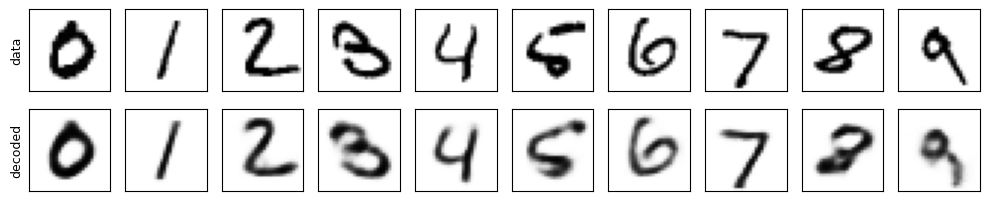

In [14]:
def show_row(axes, images, title=None):
    for ax, image in zip(axes, images):
        ax.imshow(np.asarray(image).reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
    if title:
        axes[0].set_ylabel(title, fontsize=9)

def decode_mean(model, x):
    with torch.no_grad():
        mean, _ = model.encode(x)
        return torch.sigmoid(model.decoder(mean)).cpu().numpy()

fig, axes = plt.subplots(2, 10, figsize=(10, 2.3))
show_row(axes[0], X_test[first_of_each], 'data')
show_row(axes[1], decode_mean(vae, X_te[first_of_each]), 'decoded')
plt.tight_layout(); plt.show()

Every digit comes back recognizable, and every one is softened. Thick
strokes of the 0, 1, and 7 survive almost intact; the loops of the 8 and the
top of the 9 are smeared, and the idiosyncratic 5 is returned as a more
ordinary 5. This is the blur described on the slide *Reconstructions:
Recognizable and Blurry*: when the code cannot pin down exactly where a
stroke is, the pixel probabilities that minimize the expected cross-entropy
spread the stroke over its likely positions.

### B5b. Samples from the prior

Generation uses no encoder: draw $z\sim p(z)=\mathcal N(0,I_{20})$ and decode.
The cell decodes 40 prior draws and shows the pixel probabilities, which is
what papers usually display (drawing actual 0/1 pixels from those
probabilities would add salt-and-pepper noise).

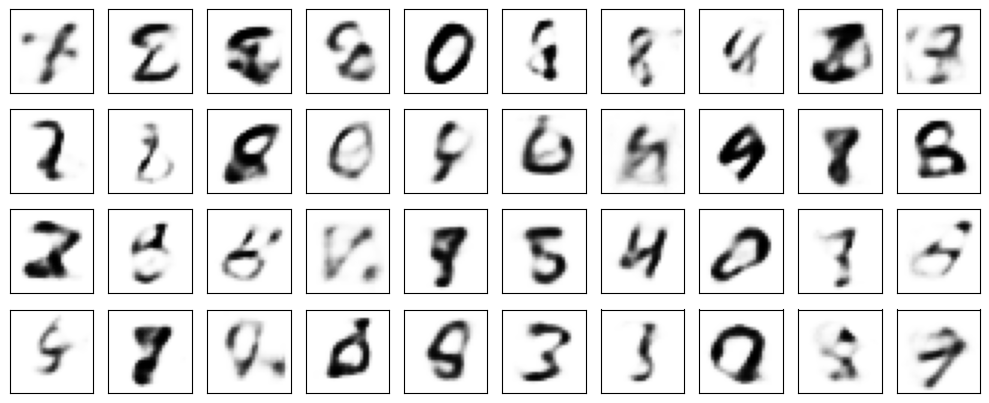

In [15]:
torch.manual_seed(SEED + 1)
with torch.no_grad():
    prior_draws = torch.sigmoid(vae.decoder(torch.randn(40, 20, device=device))).cpu().numpy()
fig, axes = plt.subplots(4, 10, figsize=(10, 4.2))
show_row(axes.ravel(), prior_draws)
plt.tight_layout(); plt.show()

Many prior draws are clean digits, such as the 0s, 8s, 9s, 3, and 5, but a
sizeable share are blends of two shapes or strokes that are no digit at all.
A 20-dimensional Gaussian has a lot of volume, and the encoder does not
spread the training codes over all of it evenly, so some prior draws land
where few training codes sit and the decoder has little to go on. The KL
term pulls the codes towards the prior; at a finite fit it does not get them
all the way there.

### B5c. How much each code coordinate carries

Because both $q_\phi$ and $p$ are diagonal, the KL term splits into one term
per coordinate,
$\tfrac12(\mu_j^2+\sigma_j^2-1-\log\sigma_j^2)$. Averaged over the test images
this says how many nats coordinate $j$ spends describing the image. A
coordinate whose average KL is near zero has $q_\phi(z_j\mid x)\approx p(z_j)$
for every image: it carries nothing, and the decoder learns to ignore it. This
is posterior collapse confined to one coordinate, and the slide *Posterior
Collapse* recommends exactly this diagnostic.

The cell computes the 20 averages, sorts them, and counts the coordinates
above 0.05 nats. It also reports a second activity measure from Burda et al.
(2016), the variance across images of the posterior mean $\mu_{\phi,j}(x)$,
which is near zero for a coordinate whose mean does not move with the
input.

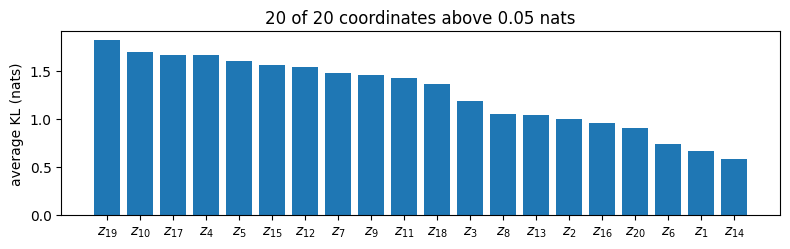

KL per coordinate (sorted): [1.82 1.7  1.66 1.66 1.6  1.56 1.54 1.47 1.46 1.42 1.36 1.18 1.05 1.04
 0.99 0.96 0.9  0.74 0.66 0.59]
sum 25.37 nats  (the test KL from Section B4 is 25.37)
variance of the posterior mean across images, min and max: 0.67 1.094


In [16]:
def per_coordinate_kl(model, X):
    with torch.no_grad():
        mean, log_variance = model.encode(X)
        kl = 0.5 * (mean**2 + log_variance.exp() - 1 - log_variance)
    return kl.mean(0).cpu().numpy(), mean.var(0).cpu().numpy()

kl_coord, activity = per_coordinate_kl(vae, X_te)
order = np.argsort(kl_coord)[::-1]
active = int((kl_coord > 0.05).sum())
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.bar(range(20), kl_coord[order], color=['C0' if k > 0.05 else 'lightgray' for k in kl_coord[order]])
ax.set(xticks=range(20), xticklabels=[f'$z_{{{j + 1}}}$' for j in order],
       ylabel='average KL (nats)', title=f'{active} of 20 coordinates above 0.05 nats')
plt.tight_layout(); plt.show()
print('KL per coordinate (sorted):', kl_coord[order].round(2))
print(f'sum {kl_coord.sum():.2f} nats  (the test KL from Section B4 is {final.test_kl:.2f})')
print('variance of the posterior mean across images, min and max:',
      activity.min().round(3), activity.max().round(3))
assert abs(kl_coord.sum() - final.test_kl) < 0.01

All 20 coordinates are active at $\beta=1$: the average KL per coordinate
ranges from 0.59 to 1.82 nats, and the 20 values sum to 25.37, the test KL of
Section B4 (the assert checks this to two decimals). The variance of the
posterior mean across images is between 0.67 and 1.09 for every coordinate,
so each $\mu_{\phi,j}(x)$ really does move with the image. With this decoder
and ten epochs nothing has collapsed. Section B7 shows coordinates switching
off as soon as the KL is weighted more heavily.

### B5d. How loose is the bound?

The ELBO satisfies $\mathcal L(x)=\log p_\theta(x)-D_{\rm KL}(q_\phi(z\mid x)\,\|\,p_\theta(z\mid x))$,
so it sits below $\log p_\theta(x)$ by the KL from the encoder's Gaussian to
the true posterior. Since $p_\theta(x)$ has no closed form, we estimate it by
**importance sampling** with the encoder as proposal:
$$p_\theta(x)=\mathbb E_{z\sim q_\phi(\cdot\mid x)}\!\left[\frac{p(z)\,p_\theta(x\mid z)}{q_\phi(z\mid x)}\right]
\approx\frac1K\sum_{k=1}^K w_k,\qquad w_k=\frac{p(z_k)\,p_\theta(x\mid z_k)}{q_\phi(z_k\mid x)} .$$
The average of $\log w_k$ estimates the ELBO; the logarithm of the average of
$w_k$ is the importance-weighted bound of Burda et al. (2016), which is still
a lower bound on $\log p_\theta(x)$ (by Jensen's inequality) but tightens
towards it as $K$ grows. The cell uses $K=200$ draws for each of 1,000 test
images, computing $\log\frac1K\sum_k w_k$ with log-sum-exp as in Lecture 16.
Look at the size of the gap, in nats per image.

In [17]:
def log_weights(model, x, K):
    """log p(z_k) + log p(x|z_k) - log q(z_k|x) for K draws per image: shape [K, B]."""
    with torch.no_grad():
        mean, log_variance = model.encode(x)
        std = torch.exp(0.5 * log_variance)
        prior = Normal(torch.zeros_like(mean), torch.ones_like(mean))
        rows = []
        for _ in range(K):
            z = mean + std * torch.randn_like(mean)
            log_px_given_z = -F.binary_cross_entropy_with_logits(
                model.decoder(z), x, reduction='none').sum(1)
            rows.append(log_px_given_z + prior.log_prob(z).sum(1)
                        - Normal(mean, std).log_prob(z).sum(1))
    return torch.stack(rows)

torch.manual_seed(SEED + 2)
K = 200
subset = X_te[:1000]
w = log_weights(vae, subset, K)
elbo_estimate = w.mean(0)                                   # average of log w
iw_estimate = torch.logsumexp(w, 0) - np.log(K)             # log of average w
gap = (iw_estimate - elbo_estimate).cpu().numpy()
print(f'ELBO, averaged over 1,000 test images:            {elbo_estimate.mean():8.2f} nats')
print(f'importance-weighted estimate of log p(x), K={K}: {iw_estimate.mean():8.2f} nats')
print(f'gap per image: mean {gap.mean():.2f}, median {np.median(gap):.2f}, '
      f'smallest {gap.min():.2f}, largest {gap.max():.2f}')
for k in [1, 10, 50, 200]:
    print(f'  K={k:3d}: {(torch.logsumexp(w[:k], 0) - np.log(k)).mean():8.2f}')
assert (gap >= 0).all() and gap.mean() > 1

ELBO, averaged over 1,000 test images:             -105.15 nats
importance-weighted estimate of log p(x), K=200:  -100.53 nats
gap per image: mean 4.62, median 4.29, smallest 1.48, largest 13.55
  K=  1:  -105.17
  K= 10:  -101.95
  K= 50:  -101.04
  K=200:  -100.53


On these 1,000 test images the ELBO averages $-105.15$ nats and the
importance-weighted estimate with $K=200$ averages $-100.53$, so the bound
sits about **4.6 nats** below the best estimate of $\log p_\theta(x)$ we can
compute. The gap is positive for every image, from 1.5 to 13.6 nats, with
median 4.3. This is the gap of the slide *The Gap Is the Price of a
Convenient Family*, measured on a fitted model: the encoder's diagonal
Gaussian is a good approximation to the true posterior, and it is still an
approximation. The $K$ column shows the estimate climbing as $K$ grows,
$-105.17$ at $K=1$ (the ELBO itself), then $-101.95$, $-101.04$, and
$-100.53$, with shrinking increments; the true $\log p_\theta(x)$ lies somewhat
above the last value.

## B6. A two-dimensional code you can see

Twenty code coordinates cannot be drawn. With $r=2$ the code space is a
plane, and every image's posterior mean is a point in it. A 2-D code is far
too small for MNIST, so the reconstructions will be worse; that is the price
of a picture. We widen the hidden layer to 512 units, as in Kingma and
Welling's Figure 4, and train for 10 epochs.

In [18]:
TWO_D_EPOCHS = 10
vae_2d, history_2d = train_vae(latent=2, hidden=512, epochs=TWO_D_EPOCHS)
final_2d = history_2d.iloc[-1]
assert final_2d.test_rec + final_2d.test_kl < 160

epoch  1  train rec 181.75 KL  5.54  |  test rec 164.33 KL  5.05  -ELBO 169.38  elapsed   1.8s


epoch  2  train rec 160.93 KL  5.32  |  test rec 157.77 KL  5.44  -ELBO 163.22  elapsed   3.7s


epoch  3  train rec 156.68 KL  5.45  |  test rec 155.21 KL  5.44  -ELBO 160.65  elapsed   5.4s


epoch  4  train rec 154.16 KL  5.53  |  test rec 153.40 KL  5.59  -ELBO 158.99  elapsed   7.4s


epoch  5  train rec 152.39 KL  5.60  |  test rec 151.58 KL  5.50  -ELBO 157.08  elapsed   9.5s


epoch  6  train rec 151.06 KL  5.66  |  test rec 150.45 KL  5.63  -ELBO 156.08  elapsed  11.5s


epoch  7  train rec 149.94 KL  5.72  |  test rec 149.39 KL  5.83  -ELBO 155.22  elapsed  13.3s


epoch  8  train rec 149.06 KL  5.77  |  test rec 148.89 KL  5.79  -ELBO 154.68  elapsed  15.3s


epoch  9  train rec 148.21 KL  5.80  |  test rec 148.23 KL  5.71  -ELBO 153.94  elapsed  17.3s


epoch 10  train rec 147.52 KL  5.85  |  test rec 147.62 KL  5.75  -ELBO 153.37  elapsed  19.2s


The 2-D model reaches a test negative ELBO of 153.4 nats after 10 epochs
(reconstruction 147.6, KL 5.8), against 105.7 for the 20-dimensional model.
The extra 48 nats are the cost of describing a digit with two numbers. The KL
is small because two coordinates can only carry a few nats. Training took
20 to 30 seconds and the curve is still falling by about half a nat per
epoch.

### B6a. The code space, coloured by digit

The cell plots the posterior means $\mu_\phi(x)$ of all 10,000 test images,
coloured by their label, together with the circle of radius 2 that holds
about 86% of the prior's mass. The model never saw a label.

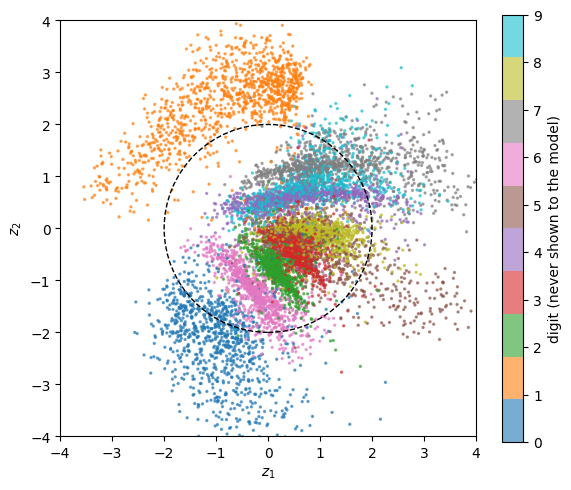

share of posterior means inside radius 2: 0.724   (prior mass inside: 0.865)
mean of the codes: [0.338 0.015]   standard deviation: [1.044 1.343]


digit,0,1,2,3,4,5,6,7,8,9
z1,-0.89,-0.77,0.17,0.50,0.70,1.07,-0.19,1.35,0.87,0.74
z2,-2.13,2.33,-0.76,-0.38,0.55,-0.47,-1.20,1.14,-0.15,0.77


In [19]:
with torch.no_grad():
    codes_2d = vae_2d.encode(X_te)[0].cpu().numpy()

fig, ax = plt.subplots(figsize=(6, 5))
scatter = ax.scatter(codes_2d[:, 0], codes_2d[:, 1], c=y_test, cmap='tab10', s=2, alpha=0.6)
ax.add_patch(plt.Circle((0, 0), 2, fill=False, color='k', ls='--', lw=1))
bar = fig.colorbar(scatter, ax=ax, ticks=range(10)); bar.set_label('digit (never shown to the model)')
ax.set(xlabel='$z_1$', ylabel='$z_2$', xlim=(-4, 4), ylim=(-4, 4), aspect='equal')
plt.tight_layout(); plt.show()

inside = (np.linalg.norm(codes_2d, axis=1) < 2).mean()
print(f'share of posterior means inside radius 2: {inside:.3f}   (prior mass inside: {1 - np.exp(-2):.3f})')
print('mean of the codes:', codes_2d.mean(0).round(3), '  standard deviation:', codes_2d.std(0).round(3))
centroids = pd.DataFrame(codes_2d).groupby(y_test).mean().round(2)
centroids.columns = ['z1', 'z2']; centroids.index.name = 'digit'
display(centroids.T)

Without seeing a label, the encoder has put the digits into
distinguishable regions: 1s in the upper left, 0s in the lower left, 7s on
the right, 6s between the 0s and the centre, and 2, 3, 5, and 8 overlapping
in the middle, where they share strokes. The 4s and 9s lie on top of each
other in one band, the pair that also confused the classifier of
Lecture 11. The cloud is roughly centred, with mean $(0.34, 0.02)$ and
standard deviations 1.04 and 1.34, somewhat wider than the prior: 72.4% of
the posterior means lie inside radius 2, against 86.5% of prior mass. The
KL term has pulled the codes towards $\mathcal N(0,I)$ without making them
exactly prior-distributed; this is the slide *The Code Space, Coloured by
Digit* on full-size MNIST.

### B6b. The decoded manifold (Kingma and Welling, Figure 4b)

The deck shows Kingma and Welling's picture of a 2-D VAE on MNIST as a
credited image. Here we make our own. Equally spaced points in the plane would
waste most of the grid on the prior's sparse tails, so the paper spaces them
by the prior's quantiles: take $u$ on an even grid in $(0,1)$ and set
$z=\Phi^{-1}(u)$, where $\Phi$ is the standard normal CDF. The cell decodes a
$20\times20$ grid of such codes into one image.

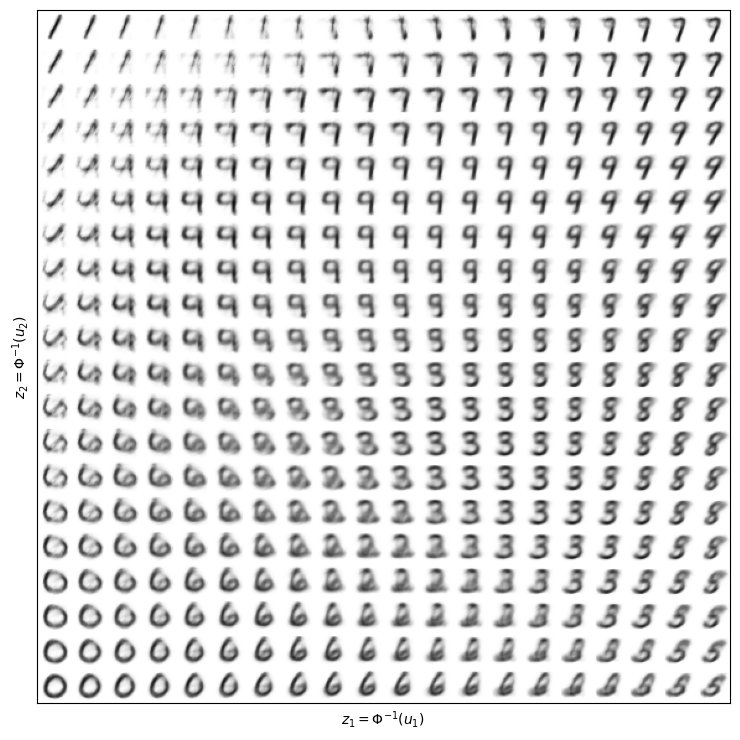

In [20]:
steps = 20
grid = norm.ppf(np.linspace(0.05, 0.95, steps))
canvas = np.zeros((28 * steps, 28 * steps))
with torch.no_grad():
    for row, z2 in enumerate(grid[::-1]):              # z2 increases upwards
        codes = torch.tensor(np.c_[grid, np.full(steps, z2)], dtype=torch.float32, device=device)
        images = torch.sigmoid(vae_2d.decoder(codes)).cpu().numpy()
        for column, image in enumerate(images):
            canvas[28 * row:28 * (row + 1), 28 * column:28 * (column + 1)] = image.reshape(28, 28)
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(canvas, cmap='gray_r', vmin=0, vmax=1)
ax.set(xticks=[], yticks=[], xlabel='$z_1=\\Phi^{-1}(u_1)$', ylabel='$z_2=\\Phi^{-1}(u_2)$')
plt.tight_layout(); plt.show()

The grid morphs smoothly in every direction, and every location decodes to
something digit-like: 1s in the top-left corner, 7s along the top right, a
broad region of 9s (with 4-like shapes at its left edge), 0s and 6s at the
bottom left, 2s and 3s in the lower middle, and 5s and 8s on the right. Each
neighbouring pair of tiles differs only slightly. Compare the picture with
the Kingma and Welling figure on the slide: the layout of the digits
depends on the random seed, while the smooth tiling of the plane is the
same.

### B6c. Walking between two digits

Pick two test images, encode both, and decode codes on the straight segment
between their posterior means. Each intermediate code is one the decoder
was trained to handle, because the KL term pulled the codes of all training
images into one connected cloud around the origin.

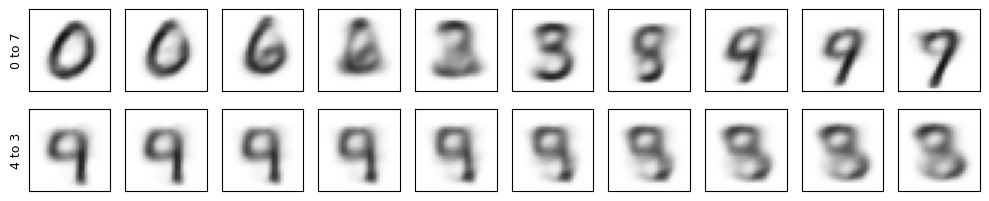

In [21]:
pairs = [(first_of_each[0], first_of_each[7]), (first_of_each[4], first_of_each[3])]
fig, axes = plt.subplots(len(pairs), 10, figsize=(10, 2.3))
for axis_row, (a, b) in zip(axes, pairs):
    with torch.no_grad():
        za, zb = vae_2d.encode(X_te[[a, b]])[0]
        path = torch.stack([za + t * (zb - za) for t in torch.linspace(0, 1, 10)])
        images = torch.sigmoid(vae_2d.decoder(path)).cpu().numpy()
    show_row(axis_row, images, f'{y_test[a]} to {y_test[b]}')
plt.tight_layout(); plt.show()

The walk from the 0 to the 7 passes through a 6, a 2, a 3, and a 9: on a
straight line through the code space it visits the digits that lie between
them in the plot of B6a, and every intermediate image is a plausible digit
shape. The second row starts from the first test 4, which this 2-D model
already reconstructs as a 9, and moves into the 8/3 region. Two code
coordinates are not enough to keep 4 and 9 apart.

### B6d. The same network without the KL term: a plain autoencoder

Remove the sampling and the KL. The encoder returns one code $z=\mu_\phi(x)$,
and the loss is the reconstruction alone. This is the deterministic
autoencoder: it compresses well, and nothing in its loss tells the codes
where to sit. The cell trains one with the same layers ($784\to512\to2$ and
back) for the same number of epochs, then compares the two code spaces and
decodes 20 draws from $\mathcal N(0,I_2)$ with each decoder.

autoencoder trained in 16.6s; test reconstruction 145.15 nats (VAE: 147.62)
autoencoder code mean [-0.31  4.55]  sd [3.64 7.46]
VAE code mean         [0.34 0.02]  sd [1.04 1.34]
share of codes inside radius 2: autoencoder 0.212, VAE 0.724


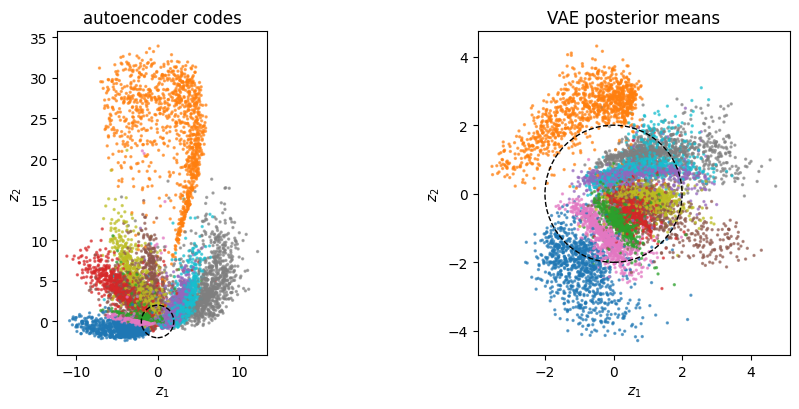

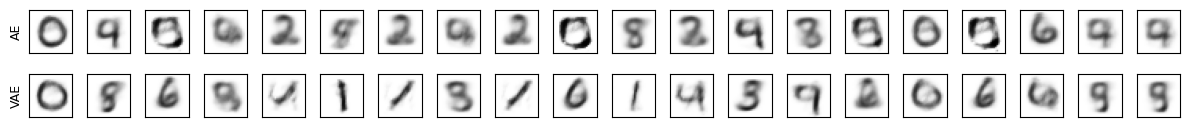

In [22]:
class Autoencoder(nn.Module):
    def __init__(self, latent=2, hidden=512):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(), nn.Linear(hidden, 784))
    def forward(self, x):
        return self.decoder(self.encoder(x))

torch.manual_seed(SEED)
ae = Autoencoder().to(device)
optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
generator = torch.Generator().manual_seed(SEED)
start = time.time()
for epoch in range(TWO_D_EPOCHS):
    order = torch.randperm(len(X_tr), generator=generator).to(device)
    for first in range(0, len(X_tr), 128):
        x = X_tr[order[first:first + 128]]
        loss = F.binary_cross_entropy_with_logits(ae(x), x, reduction='sum') / len(x)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
ae.eval()
with torch.no_grad():
    codes_ae = ae.encoder(X_te).cpu().numpy()
    ae_rec = F.binary_cross_entropy_with_logits(ae(X_te), X_te, reduction='sum').item() / len(X_te)
print(f'autoencoder trained in {time.time() - start:.1f}s; test reconstruction {ae_rec:.2f} nats '
      f'(VAE: {final_2d.test_rec:.2f})')
print('autoencoder code mean', codes_ae.mean(0).round(2), ' sd', codes_ae.std(0).round(2))
print('VAE code mean        ', codes_2d.mean(0).round(2), ' sd', codes_2d.std(0).round(2))
ae_inside = (np.linalg.norm(codes_ae, axis=1) < 2).mean()
print(f'share of codes inside radius 2: autoencoder {ae_inside:.3f}, VAE {inside:.3f}')
assert ae_inside < 0.5 * inside

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, codes, title in [(axes[0], codes_ae, 'autoencoder codes'), (axes[1], codes_2d, 'VAE posterior means')]:
    ax.scatter(codes[:, 0], codes[:, 1], c=y_test, cmap='tab10', s=2, alpha=0.6)
    ax.add_patch(plt.Circle((0, 0), 2, fill=False, color='k', ls='--', lw=1))
    ax.set(title=title, xlabel='$z_1$', ylabel='$z_2$', aspect='equal')
plt.tight_layout(); plt.show()

torch.manual_seed(SEED + 3)
prior_codes = torch.randn(20, 2, device=device)
with torch.no_grad():
    from_ae = torch.sigmoid(ae.decoder(prior_codes)).cpu().numpy()
    from_vae = torch.sigmoid(vae_2d.decoder(prior_codes)).cpu().numpy()
fig, axes = plt.subplots(2, 20, figsize=(12, 1.6))
show_row(axes[0], from_ae, 'AE'); show_row(axes[1], from_vae, 'VAE')
plt.tight_layout(); plt.show()

The autoencoder reconstructs slightly better, 145.2 nats against 147.6,
because it pays no KL and decodes a code with no noise added. Its code space
is a different matter. The codes have standard deviations 3.6 and 7.5 and
reach $z_2\approx35$ for the 1s, and only 21.2% of them lie inside the
radius-2 circle where most prior draws fall (72.4% for the VAE). That circle covers one corner
of the autoencoder's code space, where the 0s, 6s, and 2s sit, so decoding
prior draws with the autoencoder produces mostly 0s, 2s, and 9-like shapes
and never a 1 or a 7. The VAE's decoded prior draws include 1s, 6s, 3s, and
9s, because its codes fill the region the prior samples from. A plain
autoencoder is a compressor; the KL term is what makes the VAE decoder a
generator.

### B6e. The true posterior against $q_\phi$

For the 2-D VAE we can do what EM did and the VAE avoids: compute the
**exact** posterior. With only two code coordinates, $p_\theta(z\mid x)\propto p(z)\,p_\theta(x\mid z)$
can be evaluated on a fine grid of codes and normalized numerically, exactly
as in A2 for PPCA. This is the deck's slide *The Gap Is the Price of a
Convenient Family*, on real data.

For five test images the cell

1. evaluates $\log p(z)+\log p_\theta(x\mid z)$ on a coarse grid over
   $[-5,5]^2$ to find where the posterior mass is, then on a fine $301\times301$
   grid over that region;
2. contours the normalized posterior at the levels $e^{-1/2}$ and $e^{-2}$ of
   its maximum (for a Gaussian these are exactly its 1- and 2-sd ellipses)
   and overlays the 1- and 2-sd ellipses of the encoder's $q_\phi(z\mid x)$;
3. computes, on the grid, $\log p_\theta(x)$, the ELBO
   $\mathbb E_{q_\phi}[\log p(z)+\log p_\theta(x\mid z)-\log q_\phi(z\mid x)]$,
   and their difference $D_{\rm KL}(q_\phi(z\mid x)\,\|\,p_\theta(z\mid x))$,
   the gap of the encoder (`gap_encoder`);
4. repeats the ELBO for a diagonal Gaussian with this image's own posterior
   mean and variances (`gap_per_image_gaussian`), the kind of $q$ that
   per-image variational inference could find without an encoder; and
5. compares $\log p_\theta(x)$ with the importance-weighted estimate of B5d
   with $K=2{,}000$, which uses $q_\phi$ as its proposal.

A sixth panel shows PPCA's posterior for the first image from A2: there the
grid contours and the formula ellipses are the same curves, and the gap is
zero.

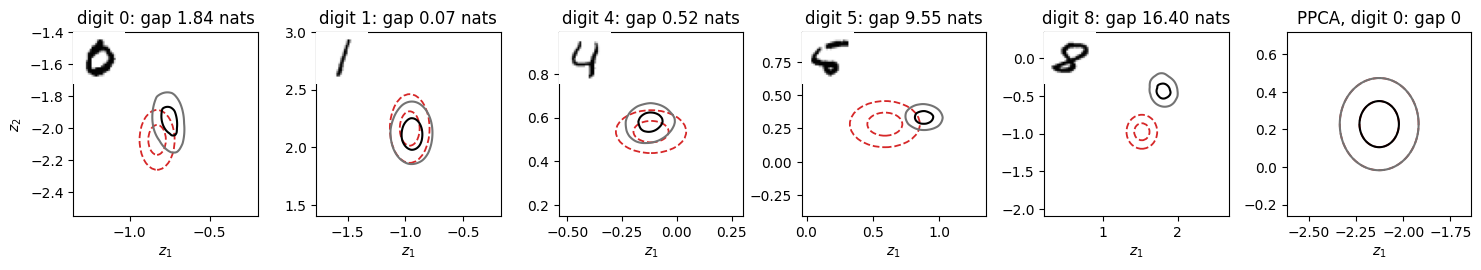

,log_p_x,ELBO,gap_encoder,gap_per_image_gaussian,importance_weighted,posterior_sd,q_sd
digit,,,,,,,
0,-136.944,-138.784,1.840,0.025,-136.878,"[0.052, 0.096]","[0.055, 0.093]"
1,-50.478,-50.550,0.071,0.003,-50.486,"[0.091, 0.136]","[0.086, 0.149]"
4,-134.900,-135.419,0.519,0.007,-134.936,"[0.057, 0.046]","[0.08, 0.049]"
5,-242.078,-251.626,9.548,0.004,-241.985,"[0.071, 0.05]","[0.132, 0.087]"
8,-205.433,-221.830,16.398,0.018,-210.454,"[0.096, 0.117]","[0.102, 0.113]"


In [23]:
def vae_log_joint(model, x):
    x_t = torch.tensor(x, dtype=torch.float32, device=device)
    def log_joint(Z):
        with torch.no_grad():
            Z_t = torch.tensor(Z, dtype=torch.float32, device=device)
            out = []
            for first in range(0, len(Z_t), 20_000):
                logits = vae_2d.decoder(Z_t[first:first + 20_000])
                log_px = -F.binary_cross_entropy_with_logits(
                    logits, x_t.expand_as(logits), reduction='none').sum(1)
                out.append(log_px - 0.5 * (Z_t[first:first + 20_000] ** 2).sum(1) - np.log(2 * np.pi))
        return torch.cat(out).double().cpu().numpy()
    return log_joint

shown_digits = [0, 1, 4, 5, 8]
rows = []
fig, axes = plt.subplots(1, len(shown_digits) + 1, figsize=(15, 3.1))
torch.manual_seed(SEED + 5)
for ax, digit in zip(axes, shown_digits):
    index = first_of_each[digit]
    x = X_test[index]
    log_joint = vae_log_joint(vae_2d, x)
    # Where is the mass? A coarse look at the whole plane first.
    c1, c2, coarse, _, _, _ = grid_posterior(log_joint, (0, 0), 5, n=201)
    heavy = np.argwhere(coarse > coarse.max() * np.exp(-14))
    low = np.array([c1[heavy[:, 1].min()], c2[heavy[:, 0].min()]])
    high = np.array([c1[heavy[:, 1].max()], c2[heavy[:, 0].max()]])
    with torch.no_grad():
        q_mean, q_log_var = vae_2d.encode(X_te[[index]])
    q_mean, q_sd = q_mean[0].cpu().numpy().astype(float), np.exp(0.5 * q_log_var[0].cpu().numpy().astype(float))
    low, high = np.minimum(low, q_mean - 4 * q_sd), np.maximum(high, q_mean + 4 * q_sd)
    centre, half = (low + high) / 2, (high - low).max() / 2 + 0.1
    g1, g2, density, post_mean, post_cov, log_px = grid_posterior(log_joint, centre, half, n=301)
    # The ELBO on the same grid, weighting by the encoder's Gaussian.
    Z = np.stack(np.meshgrid(g1, g2), -1).reshape(-1, 2)
    log_q = norm.logpdf(Z, q_mean, q_sd).sum(1)
    q_weights = np.exp(log_q - log_q.max()); q_weights /= q_weights.sum()
    values = log_joint(Z)
    elbo = q_weights @ (values - log_q)
    # The same bound for a Gaussian fitted to this image's posterior alone.
    log_q_star = norm.logpdf(Z, post_mean, np.sqrt(post_cov.diagonal())).sum(1)
    star_weights = np.exp(log_q_star - log_q_star.max()); star_weights /= star_weights.sum()
    elbo_star = star_weights @ (values - log_q_star)
    iw = (torch.logsumexp(log_weights(vae_2d, X_te[[index]], 2000)[:, 0], 0) - np.log(2000)).item()
    rows.append(dict(digit=digit, log_p_x=log_px, ELBO=elbo, gap_encoder=log_px - elbo,
                     gap_per_image_gaussian=log_px - elbo_star, importance_weighted=iw, posterior_sd=np.sqrt(post_cov.diagonal()).round(3),
                     q_sd=q_sd.round(3)))
    ax.contour(g1, g2, density, levels=density.max() * np.exp([-2, -0.5]), colors=['0.45', 'k'])
    for scale in (1, 2):
        ax.add_patch(Ellipse(q_mean, 2 * scale * q_sd[0], 2 * scale * q_sd[1], fill=False,
                             color='C3', lw=1.3, ls='--'))
    ax.set(title=f'digit {digit}: gap {log_px - elbo:.2f} nats', xlabel='$z_1$', aspect='equal')
    inset = ax.inset_axes([0.0, 0.72, 0.28, 0.28])
    inset.imshow(x.reshape(28, 28), cmap='gray_r'); inset.axis('off')
axes[0].set_ylabel('$z_2$')

# PPCA, first test image (a zero), from A2: grid contours and formula ellipses.
p1, p2, ppca_density, _, _, _ = grid_posterior(
    ppca_log_joint(x0, W2, sigma2_2), mean_formula, 4 * np.sqrt(S2.diagonal().max()), n=301)
axes[-1].contour(p1, p2, ppca_density, levels=ppca_density.max() * np.exp([-2, -0.5]), colors=['0.45', 'k'])
for scale in (1, 2):
    add_ellipse(axes[-1], mean_formula, S2, scale, color='C3', lw=1.3, ls='--')
axes[-1].set(title='PPCA, digit 0: gap 0', xlabel='$z_1$', aspect='equal')
plt.tight_layout(); plt.show()

gaps = pd.DataFrame(rows).set_index('digit')
display(gaps.round(3))
assert (gaps.gap_encoder > 0).all() and (gaps.gap_per_image_gaussian > -1e-3).all()
assert (gaps.importance_weighted <= gaps.log_p_x + 0.15).all()   # a lower bound, up to grid error

The contours of the true posterior (black at $e^{-1/2}$, grey at $e^{-2}$
of the maximum) are close to ellipses for all five images, and the table
says how close: a Gaussian fitted to each image's own posterior has a gap of
at most **0.025 nats**. The diagonal-Gaussian family is nearly good enough
here. The encoder's $q_\phi$ (red, dashed) is a different story. For the 1
and the 4 it lands on the posterior, with gaps of 0.07 and 0.52 nats. For
the 0 it sits slightly below and to the left, a gap of 1.84 nats. For the 5
it is displaced and about twice too wide, 9.55 nats, and for the 8 it misses
the posterior altogether: the two do not overlap, and the gap is
**16.40 nats**.

So almost the whole gap between the ELBO and $\log p_\theta(x)$ here comes
from **amortization**: one encoder network has to output $q$ for every image,
and for some images its output is far from the best Gaussian it could have
given. This is the cost of replacing the per-image E-step of EM by a single
function; the deck's slide *The Gap Is the Price of a Convenient Family*
shows the other cost, a family that cannot bend, which on these images is
small.

The last column shows a second consequence. Importance sampling with
$q_\phi$ as proposal agrees with the grid to within 0.1 nats wherever $q_\phi$
covers the posterior, and for the 8 it reports $-210.5$ against the grid's
$-205.4$: with no proposal draws near the posterior mass, even $K=2{,}000$
samples cannot find it. The estimate of B5d is reliable only as far as the
encoder is. For PPCA (right) the grid contours and the formula ellipses are
the same curves: the family contains the posterior, the encoder is the exact
formula, and the gap is zero.

## B7. Reweighting the KL: the $\beta$-VAE and collapsing coordinates

The two terms of the loss pull against each other: an informative code must
differ from image to image, and that is exactly what the KL charges for. The
$\beta$-VAE makes the trade explicit,
$$-\mathbb E_{q_\phi}\bigl[\log p_\theta(x\mid z)\bigr]+\beta\,D_{\rm KL}\bigl(q_\phi(z\mid x)\,\|\,p(z)\bigr),$$
with $\beta=1$ the ELBO. The cell trains the $r=20$ model of Section B4 at
$\beta\in\{0.5,1,4,16\}$ for three epochs each and reports, for each $\beta$, the test
reconstruction, the test KL, and the number of coordinates above 0.05 nats.
It then shows the KL of every coordinate and the reconstructions of the same
three test digits. Predict before running: as $\beta$ grows, what happens to
the number of active coordinates?

beta  0.5: test reconstruction  80.64  KL 33.39  active coordinates 20/20   ( 5.5s)


beta  1.0: test reconstruction  87.75  KL 24.11  active coordinates 20/20   ( 5.5s)


beta  4.0: test reconstruction 121.56  KL  8.67  active coordinates 12/20   ( 5.2s)


beta 16.0: test reconstruction 186.42  KL  0.96  active coordinates  3/20   ( 5.6s)


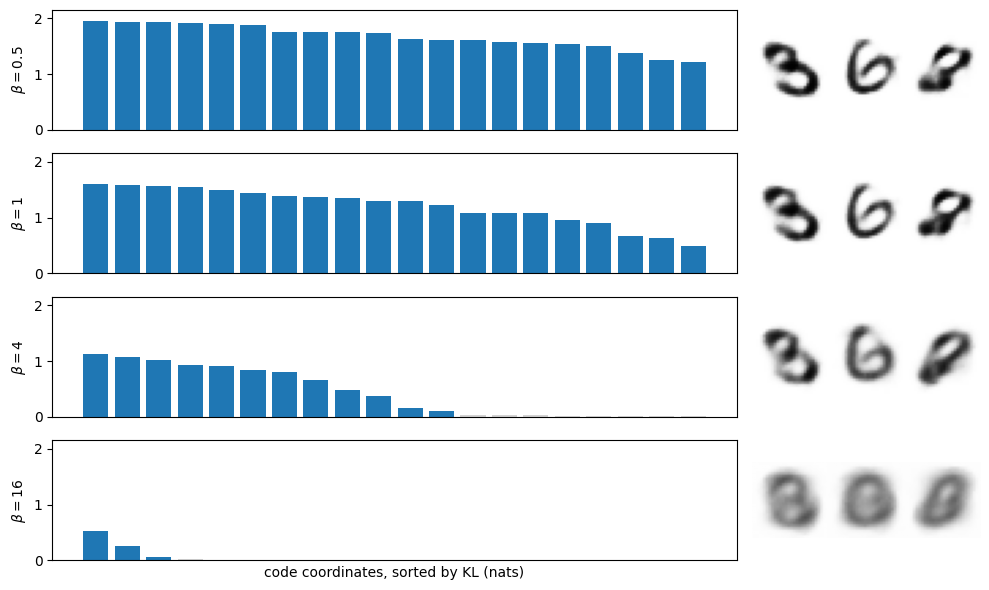

In [24]:
BETAS, BETA_EPOCHS = [0.5, 1.0, 4.0, 16.0], 3
sweep = {}
for beta in BETAS:
    start = time.time()
    model_b, history_b = train_vae(beta=beta, epochs=BETA_EPOCHS, verbose=False)
    kl_b, _ = per_coordinate_kl(model_b, X_te)
    last = history_b.iloc[-1]
    sweep[beta] = dict(model=model_b, kl=kl_b, rec=last.test_rec, total_kl=last.test_kl)
    print(f'beta {beta:4.1f}: test reconstruction {last.test_rec:6.2f}  KL {last.test_kl:5.2f}  '
          f'active coordinates {(kl_b > 0.05).sum():2d}/20   ({time.time() - start:4.1f}s)')

fig, axes = plt.subplots(len(BETAS), 2, figsize=(10, 1.5 * len(BETAS)),
                         gridspec_kw={'width_ratios': [3, 1]})
shown = [first_of_each[d] for d in (3, 6, 8)]
for row, beta in enumerate(BETAS):
    kl_b = np.sort(sweep[beta]['kl'])[::-1]
    axes[row, 0].bar(range(20), kl_b, color=['C0' if k > 0.05 else 'lightgray' for k in kl_b])
    axes[row, 0].set(ylabel=f'$\\beta={beta:g}$', xticks=[], ylim=(0, 1.1 * max(sweep[b]['kl'].max() for b in BETAS)))
    images = decode_mean(sweep[beta]['model'], X_te[shown])
    axes[row, 1].imshow(np.hstack([im.reshape(28, 28) for im in images]), cmap='gray_r', vmin=0, vmax=1)
    axes[row, 1].axis('off')
axes[-1, 0].set_xlabel('code coordinates, sorted by KL (nats)')
plt.tight_layout(); plt.show()

actives = [int((sweep[b]['kl'] > 0.05).sum()) for b in BETAS]
assert actives == sorted(actives, reverse=True) and actives[-1] < actives[0]

Raising $\beta$ trades reconstruction for KL, and the KL is shed one
coordinate at a time. At $\beta=0.5$ the model spends 33.4 nats on the code
and reconstructs to 80.6 nats; at $\beta=1$ (three epochs, so identical to
epoch 3 of Section B4) 24.1 and 87.8. At $\beta=4$ the KL falls to 8.7 nats,
and **8 of the 20 coordinates are switched off** entirely: their posterior is
the prior for every image. At $\beta=16$ only 3 coordinates carry anything,
the total KL is 0.96 nats, reconstruction rises to 186.4, and the three
decoded digits come back as nearly the same grey blob. That is posterior
collapse, the slide *What $\beta$ Does, Measured*, on MNIST. Among these four
runs the ELBO itself (reconstruction plus unweighted KL) is best at
$\beta=1$, 111.9 nats against 114.0 at $\beta=0.5$: the trade that maximizes
the bound is the one the bound itself sets.

## Summary

PPCA keeps everything EM needs in closed form. On MNIST with $r=2$ the
Tipping–Bishop fit leaves noise variance 0.056 per pixel, and the posterior
$\mathcal N(M^{-1}W^\top(x-\mu),\sigma^2M^{-1})$ agrees with Gaussian
conditioning and with brute-force normalization on a grid to every printed
digit. Its covariance is the same for every image and small (standard
deviations 0.10 and 0.12), and its mean is the PCA score shrunk by about 1%.
The linear decoder can only add fixed images, so its samples are
superpositions with noisy backgrounds.

The VAE is the ELBO of Lecture 16 with two changes: the E-step's exact
posterior is replaced by a Gaussian $q_\phi(z\mid x)$ that an encoder outputs
for any image, and the expectation in the reconstruction term is estimated
with one reparameterized draw. The KL has a closed form (Monte Carlo agrees
to within one standard error), and autograd executes exactly the pathwise
gradients of Appendix A.6. Ten epochs of the PyTorch example reach a test
negative ELBO of 105.7 nats in well under a minute on a laptop CPU, with the
reconstruction falling from 106 to 80 nats while the KL rises from 21 to 25.
Importance sampling puts $\log p_\theta(x)$ about 4.6 nats above the bound,
the price of a diagonal Gaussian posterior. A 2-D code arranges the digits
into regions without labels and decodes to a smooth manifold, at a cost of 48
nats. A plain autoencoder with the same layers reconstructs slightly better
but scatters its codes far from the prior, so it cannot generate from
$\mathcal N(0,I)$. Raising $\beta$ switches code coordinates off one at a time,
from 20 active at $\beta\le1$ to 3 at $\beta=16$. With two code coordinates
the true posterior can be computed on a grid: it is close to Gaussian (a
per-image Gaussian loses at most 0.025 nats), and the encoder's gap ranges
from 0.07 to 16.4 nats on five test images, almost all of it the price of
amortizing the E-step.

Total running time of this notebook:

In [25]:
print(f'{time.time() - NOTEBOOK_START:.0f} seconds on {device}')

88 seconds on cpu


## Try It

For each change, write down a prediction before rerunning the cells.

1. **Code size.** In Section B4, train `train_vae(latent=5)` and
   `train_vae(latent=50)`. Predict the test reconstruction and KL of each.
   Does the 50-dimensional model use all 50 coordinates (Section B5c)?
2. **More samples per image.** The reconstruction term uses one draw of $z$
   per image. Change `loss_terms` to average the reconstruction over five
   draws. Does the training curve get smoother, and does the final $-\mathcal L$
   change by more than a nat?
3. **Turn off the noise.** In `VAE.reparameterize`, return `mean` alone, so
   the decoder always sees the posterior mean, and keep the KL. Predict what
   the encoder does to $\log\sigma^2_\phi$ (look at `log_variance` after
   training), and why the KL then no longer measures the information in the
   code.
4. **A tighter importance estimate.** In Section B5d, raise $K$ to 1,000.
   Predict whether the estimate of $\log p_\theta(x)$ goes up or down, and by
   roughly how much, from the $K=1,10,50,200$ column.
5. **Binarize the data.** Replace the training targets by
   `(X_tr > 0.5).float()` and retrain. The Bernoulli likelihood is now exact.
   Predict whether the test $-\mathcal L$ on binarized test images is higher or
   lower than 105 nats, and compare it with the Bernoulli mixture of
   Lecture 16.
6. **Collapse in two dimensions.** Rerun Section B6 with `beta=6` (add the
   argument to `train_vae`). Predict the code space and the decoded
   manifold.
7. **More PPCA directions.** In A1, fit `closed_form(50)`. Predict
   $\widehat\sigma^2$ from the printed eigenvalues before running, and predict
   whether the samples of A4 look cleaner or noisier.
8. **The amortization gap.** In B6e, replace `shown_digits` by five other
   test images, for instance the images with the largest gaps in B5d. Then
   rerun B6 with `TWO_D_EPOCHS = 30`. Predict whether longer training closes
   the encoder's gap on the 8, and whether the per-image Gaussian gap
   changes.